## Agentic GIBS — Option 1 (Colab, self-contained)

Upload to `MyDrive/agentic_gibs/`:
- `results.json`
- `steps_to_annotate_all.csv`

All gibs code is inlined — no package upload needed.

In [9]:
import subprocess
subprocess.run(['pip', 'install', '-q', 'transformers', 'torch', 'accelerate',
                'scikit-learn', 'matplotlib', 'huggingface_hub', 'tqdm',
                'sentence-transformers'], check=True)

DRIVE_BASE = '/home/svelag11/agentic'

In [10]:
# ── gibs/graph/step_graph.py (inlined) ───────────────────────────────────────
import json, re
from typing import Any

ENUM_VALUES = {"yes", "no", "true", "false", "economy", "business", "basic_economy", "one_way", "round_trip"}
VALUE_TOKEN = re.compile(
    r"\d{4}-\d{2}-\d{2}"
    r"|\b[A-Z0-9]{6}\b"
    r"|\b[a-z]+_[a-z]+_\d+\b"
    r"|\b(?:gift_card|credit_card|certificate)_\d+\b"
    r"|\bHAT\d{3}\b"
)
FREE_TEXT_MIN_LEN = 40
ISO_DATE = re.compile(r"^\d{4}-\d{2}-\d{2}$")
CONTROL_TOKEN = re.compile(r"^###([A-Z_\-]+)###$")
CONTROL_TEXT = {
    "STOP": "The user ended the conversation.",
    "TRANSFER": "The user was transferred to a human agent.",
    "OUT-OF-SCOPE": "The user said the request is out of scope.",
}
UNICODE_FIXES = {"\u2010": "-", "\u2011": "-", "\u2012": "-", "\u2013": "-", "\u2014": "-",
                 "\u00a0": " ", "\u202f": " ", "\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"'}

def normalize_text(text):
    for k, v in UNICODE_FIXES.items():
        text = text.replace(k, v)
    text = text.replace("**", "").replace("__", "")
    return re.sub(r"\s+", " ", text).strip()

def _flatten(value, prefix=""):
    if isinstance(value, dict):
        out = []
        for k, v in value.items():
            out += _flatten(v, f"{prefix}.{k}" if prefix else str(k))
        return out
    if isinstance(value, list):
        if not value:
            return [(prefix, "[]")]
        out = []
        for i, v in enumerate(value):
            out += _flatten(v, f"{prefix}[{i}]")
        return out
    return [(prefix, value)]

def _scalar(v):
    return "null" if v is None else (str(v).lower() if isinstance(v, bool) else str(v))

def verbalize_tool_call(name, arguments):
    pairs = _flatten(arguments or {})
    if not pairs:
        return f"Call {name} with no arguments."
    return f"Call {name} with " + "; ".join(f"{k} = {normalize_text(_scalar(v))}" for k, v in pairs) + "."

def verbalize_observation(content, error):
    if error:
        return "Tool error: " + normalize_text(content)
    try:
        parsed = json.loads(content)
    except (json.JSONDecodeError, TypeError):
        return "Tool result: " + normalize_text(str(content))
    if isinstance(parsed, (dict, list)):
        return "Tool result: " + "; ".join(f"{k}: {normalize_text(_scalar(v))}" for k, v in _flatten(parsed)) + "."
    return "Tool result: " + normalize_text(_scalar(parsed))

def verbalize_utterance(content):
    text = (content or "").strip()
    m = CONTROL_TOKEN.match(text)
    if m:
        return CONTROL_TEXT.get(m.group(1), f"The user sent the control signal {m.group(1)}.")
    return normalize_text(text)

def _reasoning(msg):
    try:
        m = msg["raw_data"]["choices"][0]["message"]
    except (KeyError, IndexError, TypeError):
        return None
    return m.get("reasoning") or m.get("reasoning_content") or None

def _leaves(v):
    if isinstance(v, dict):
        for x in v.values(): yield from _leaves(x)
    elif isinstance(v, list):
        for x in v: yield from _leaves(x)
    else:
        yield v

def dependency_values(arguments):
    out = []
    for v in _leaves(arguments or {}):
        if not isinstance(v, str):
            continue
        if len(v) >= FREE_TEXT_MIN_LEN:
            cands = VALUE_TOKEN.findall(v)
        elif len(v) < 3 or v.lower() in ENUM_VALUES:
            cands = []
        else:
            cands = [v]
        for c in cands:
            if c not in out:
                out.append(c)
    return out

def value_occurs(value, text):
    left = r"(?<![A-Za-z0-9])"
    right = r"(?![A-Za-z0-9])" if not ISO_DATE.match(value) else r"(?![A-SU-Za-z0-9])"
    return re.search(left + re.escape(value) + right, text) is not None

def _visible_text(node):
    if node["type"] == "UserTurn":
        return node.get("content") or ""
    if node.get("kind") == "tool_call":
        return node["observation"]["content_raw"] or ""
    return node.get("content") or ""

def build_step_graph(sim, info=None, task=None, source_file=None):
    msgs = sim.get("messages") or []
    nodes = []
    step_index = 0
    i = 0
    while i < len(msgs):
        m = msgs[i]
        role = m["role"]
        if role == "user":
            nodes.append({
                "id": f"u{i}", "type": "UserTurn", "scorable": False,
                "raw_message_indices": [i], "turn_idx": m.get("turn_idx"), "timestamp": m.get("timestamp"),
                "content": m.get("content"),
                "op_text": verbalize_utterance(m.get("content")),
                "result_text": verbalize_utterance(m.get("content")),
            })
        elif role == "assistant":
            node = {
                "id": f"s{i}", "type": "AgentStep", "scorable": True, "step_index": step_index,
                "raw_message_indices": [i], "turn_idx": m.get("turn_idx"), "timestamp": m.get("timestamp"),
                "reasoning": _reasoning(m), "content": m.get("content"),
            }
            calls = m.get("tool_calls") or []
            if len(calls) > 1:
                raise ValueError(f"message {i}: parallel tool calls not supported")
            if calls:
                tc = calls[0]
                if i + 1 >= len(msgs) or msgs[i+1]["role"] != "tool" or msgs[i+1].get("id") != tc["id"]:
                    raise ValueError(f"message {i}: tool call {tc['id']} has no immediately following observation")
                obs = msgs[i+1]
                try:
                    parsed = json.loads(obs["content"])
                except (json.JSONDecodeError, TypeError):
                    parsed = None
                node.update({
                    "kind": "tool_call",
                    "tool_call": {"id": tc["id"], "name": tc["name"], "arguments": tc.get("arguments") or {}},
                    "observation": {"tool_call_id": obs["id"], "error": bool(obs.get("error")),
                                    "raw_message_index": i+1, "timestamp": obs.get("timestamp"),
                                    "content_raw": obs["content"], "content_parsed": parsed},
                    "op_text": verbalize_tool_call(tc["name"], tc.get("arguments") or {}),
                    "result_text": verbalize_observation(obs["content"], bool(obs.get("error"))),
                })
                node["raw_message_indices"].append(i+1)
                i += 1
            else:
                node.update({"kind": "message",
                             "op_text": verbalize_utterance(m.get("content")),
                             "result_text": verbalize_utterance(m.get("content"))})
            nodes.append(node)
            step_index += 1
        else:
            raise ValueError(f"message {i}: unpaired role {role!r}")
        i += 1

    for k, n in enumerate(nodes):
        if n["type"] != "AgentStep": continue
        if n["kind"] == "tool_call":
            n["response_node"] = n["id"]
        else:
            nxt = nodes[k+1] if k+1 < len(nodes) else None
            n["response_node"] = nxt["id"] if nxt and nxt["type"] == "UserTurn" else None

    edges = [{"id": f"t{k}", "type": "temporal", "source": a["id"], "target": b["id"]}
             for k, (a, b) in enumerate(zip(nodes, nodes[1:]))]
    dep_count = 0
    for k, n in enumerate(nodes):
        if n.get("kind") != "tool_call": continue
        grouped = {}
        for value in dependency_values(n["tool_call"]["arguments"]):
            hits = [p["id"] for p in nodes[:k] if value_occurs(value, _visible_text(p))]
            if not hits: continue
            src = hits[0]
            g = grouped.setdefault(src, {"values": [], "alternative_sources": {}})
            g["values"].append(value)
            if hits[1:]: g["alternative_sources"][value] = hits[1:]
        for src, g in grouped.items():
            edges.append({"id": f"d{dep_count}", "type": "data_dependency", "source": src, "target": n["id"],
                          "values": g["values"], "alternative_sources": g["alternative_sources"],
                          "rule": "earliest prior node whose raw visible text contains the value"})
            dep_count += 1

    info = info or {}
    ri = sim.get("reward_info") or {}
    reward = ri.get("reward")
    metadata = {
        "source_file": source_file, "simulation_id": sim.get("id"),
        "task_id": str(sim.get("task_id")), "trial": sim.get("trial"),
        "reward": reward, "success": None if reward is None else reward >= 0.5,
    }
    return {"schema_version": "0.2",
            "graph_id": f"task{metadata['task_id']}_{str(sim.get('id'))[:8]}",
            "metadata": metadata, "nodes": nodes, "edges": edges}

print('step_graph ready')

step_graph ready


In [11]:
# ── gibs/mcs/nli.py (inlined, essential parts only) ──────────────────────────
import hashlib, os
from pathlib import Path

DEFAULT_CACHE_DIR = Path(os.environ.get("STEPWISE_NLI_CACHE", Path.home() / ".cache" / "stepwise_nli"))

def symmetric_input_ids(tokenizer, a, b, max_length):
    full = tokenizer(f"{a} [SEP] {b}", truncation=False)["input_ids"]
    cls, sep = tokenizer.cls_token_id, tokenizer.sep_token_id
    mid = full.index(sep, 1)
    end = mid
    while full[end+1] == sep and end+1 < len(full)-1:
        end += 1
    sep_block = full[mid:end+1]
    ids_a, ids_b = full[1:mid], full[end+1:-1]
    budget = max_length - 2 - len(sep_block)
    la, lb = len(ids_a), len(ids_b)
    if la + lb <= budget:
        ka, kb = la, lb
    else:
        half = budget // 2
        if la <= half:   ka, kb = la, budget - la
        elif lb <= half: ka, kb = budget - lb, lb
        else:            ka, kb = half, budget - half
    return [cls] + ids_a[:ka] + sep_block + ids_b[:kb] + [sep]


class DebertaEntailment:
    def __init__(self, model_name="microsoft/deberta-large-mnli", device=None,
                 batch_size=16, cache_dir=DEFAULT_CACHE_DIR, overlength="symmetric"):
        import torch
        from transformers import AutoModelForSequenceClassification, AutoTokenizer
        self.overlength = overlength
        self.truncated = set()
        self.n_forward = 0
        self.n_requested = 0
        self.torch = torch
        self.model_name = model_name
        self.batch_size = batch_size
        if device is None:
            if torch.cuda.is_available():    self.device = "cuda"
            elif torch.backends.mps.is_available(): self.device = "mps"
            else:                            self.device = "cpu"
        else:
            self.device = device
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModelForSequenceClassification.from_pretrained(model_name, torch_dtype=torch.float32)
        self.model.to(self.device).eval()
        labels = {v.lower(): int(k) for k, v in self.model.config.id2label.items()}
        self.entail_index = labels["entailment"]
        try:
            from huggingface_hub import snapshot_download
            self.revision = Path(snapshot_download(model_name, local_files_only=True)).name
        except Exception:
            self.revision = getattr(self.model.config, "_commit_hash", None) or "unknown"
        self.max_length = min(self.tokenizer.model_max_length, self.model.config.max_position_embeddings)
        self.cache = {}
        self.cache_file = None
        if cache_dir is not None:
            cache_dir = Path(cache_dir)
            cache_dir.mkdir(parents=True, exist_ok=True)
            tag = f"{model_name.replace('/', '__')}__{self.revision[:12]}__code_sep_string"
            self.cache_file = cache_dir / f"{tag}.jsonl"
            if self.cache_file.exists():
                with open(self.cache_file) as f:
                    for line in f:
                        rec = json.loads(line)
                        self.cache[rec["k"]] = rec["p"]
        print(f"{model_name} | {self.device} | cache: {len(self.cache)} entries")

    def _key(self, a, b, truncated=False):
        tag = "" if not truncated else chr(0) + "symmetric"
        return hashlib.sha256(f"{a}\x00{b}{tag}".encode()).hexdigest()

    def token_length(self, a, b):
        return len(self.tokenizer(f"{a} [SEP] {b}", truncation=False)["input_ids"])

    def encode(self, pairs, pad=True, truncate=False):
        if truncate and self.overlength == "symmetric":
            rows = [symmetric_input_ids(self.tokenizer, a, b, self.max_length) for a, b in pairs]
            width = max(len(r) for r in rows)
            pad_id = self.tokenizer.pad_token_id
            ids  = self.torch.tensor([r + [pad_id]*(width-len(r)) for r in rows])
            mask = self.torch.tensor([[1]*len(r) + [0]*(width-len(r)) for r in rows])
            return {"input_ids": ids, "attention_mask": mask}
        kw = {"return_tensors": "pt", "padding": True} if pad else {}
        kw.update({"truncation": True, "max_length": self.max_length} if truncate else {"truncation": False})
        return self.tokenizer([f"{a} [SEP] {b}" for a, b in pairs], **kw)

    def entail_batch(self, pairs):
        unique = list(dict.fromkeys(pairs))
        self.n_requested += len(unique)
        long = {(a, b) for a, b in unique if self.token_length(a, b) > self.max_length}
        self.truncated |= long
        new = []
        with self.torch.no_grad():
            for truncate in (False, True):
                todo = [p for p in unique if (p in long)==truncate and self._key(*p, truncate) not in self.cache]
                for i in range(0, len(todo), self.batch_size):
                    chunk = todo[i:i+self.batch_size]
                    enc = {k: v.to(self.device) for k, v in self.encode(chunk, truncate=truncate).items()}
                    probs = self.torch.softmax(self.model(**enc).logits.float(), dim=-1)[:, self.entail_index]
                    self.n_forward += len(chunk)
                    for (a, b), p in zip(chunk, probs.cpu().tolist()):
                        self.cache[self._key(a, b, truncate)] = p
                        new.append({"k": self._key(a, b, truncate), "p": p})
        if new and self.cache_file is not None:
            with open(self.cache_file, "a") as f:
                for rec in new:
                    f.write(json.dumps(rec) + "\n")
        return [self.cache[self._key(a, b, (a,b) in long)] for a, b in pairs]

    def describe(self):
        return {"model": self.model_name, "device": self.device}


class Similarity:
    def __init__(self, model, direction="max_bidirectional"):
        self.model = model
        self.direction = direction
        self._memo = {}

    def prefetch(self, pairs):
        pairs = [p for p in dict.fromkeys(pairs) if p not in self._memo]
        if not pairs: return
        fwd = self.model.entail_batch(pairs)
        bwd = self.model.entail_batch([(b, a) for a, b in pairs]) if self.direction == "max_bidirectional" else [None]*len(pairs)
        for p, f, b in zip(pairs, fwd, bwd):
            self._memo[p] = (f, b)

    def __call__(self, a, b):
        if (a, b) not in self._memo:
            self.prefetch([(a, b)])
        f, b_ = self._memo[(a, b)]
        return f if b_ is None else max(f, b_)

print('nli ready')

nli ready


In [12]:
# ── gibs/mcs/mcs.py + consensus.py (inlined, essential parts) ────────────────
from dataclasses import dataclass, field
from collections import deque

ROOT = "ROOT"

@dataclass
class ProjectedGraph:
    graph_id: str
    topology: str
    nodes: dict = field(default_factory=dict)
    edges: list = field(default_factory=list)

    def out_edges(self, nid): return [e for e in self.edges if e["src"] == nid]
    def in_edges(self, nid):  return [e for e in self.edges if e["dst"] == nid]

def node_id_for(event_id): return f"N:{event_id}"

def _node_kind(step_node):
    if step_node["type"] == "UserTurn": return "user_turn"
    return "tool_result" if step_node["kind"] == "tool_call" else "agent_message"


@dataclass
class MCSConfig:
    tau_v: float = 0.7
    tau_e: float = 0.7
    top_k: int = 10

@dataclass
class MCSResult:
    query_id: str
    ref_id: str
    node_map: dict   # query_node_id -> ref_node_id
    edge_map: dict   # query_edge_id -> ref_edge_id
    size: int


def _node_sim(nq, nr, sim_fn):
    if nq["id"] == ROOT and nr["id"] == ROOT: return 1.0
    if nq["id"] == ROOT or nr["id"] == ROOT:  return 0.0
    if nq["text"] is None or nr["text"] is None: return 1.0
    return sim_fn(nq["text"], nr["text"])


def _edge_score(eq, er, gq, gr, sim_fn, cfg):
    e_sim = sim_fn(eq["text"] or "", er["text"] or "") if (eq["text"] and er["text"]) else 1.0
    if e_sim < cfg.tau_e: return 0.0
    t_sim = _node_sim(gq.nodes[eq["dst"]], gr.nodes[er["dst"]], sim_fn)
    if t_sim < cfg.tau_v: return 0.0
    s_sim = _node_sim(gq.nodes[eq["src"]], gr.nodes[er["src"]], sim_fn)
    if s_sim < cfg.tau_v: return 0.0
    return e_sim + t_sim + s_sim


def find_mcs(gq, gr, sim_fn, cfg=None):
    if cfg is None: cfg = MCSConfig()
    q_edges = [e for e in gq.edges if e["scorable"]]
    r_edges = [e for e in gr.edges if e["scorable"]]

    scores = {}
    pairs_to_prefetch = []
    for eq in q_edges:
        for er in r_edges:
            for ta, tb in [(eq["text"] or "", er["text"] or ""),
                           (gq.nodes[eq["dst"]]["text"] or "", gr.nodes[er["dst"]]["text"] or ""),
                           (gq.nodes[eq["src"]]["text"] or "", gr.nodes[er["src"]]["text"] or "")]:
                if ta and tb: pairs_to_prefetch.extend([(ta, tb), (tb, ta)])
    sim_fn.prefetch(pairs_to_prefetch)

    for eq in q_edges:
        for er in r_edges:
            s = _edge_score(eq, er, gq, gr, sim_fn, cfg)
            if s > 0: scores[(eq["id"], er["id"])] = s

    seeds = sorted(scores, key=scores.__getitem__, reverse=True)[:cfg.top_k]

    best_node_map, best_edge_map, best_size = {}, {}, 0

    for seed in seeds:
        qe_id, re_id = seed
        node_map = {}
        edge_map = {}

        def try_add_edge(qe_id, re_id):
            eq = next(e for e in gq.edges if e["id"] == qe_id)
            er = next(e for e in gr.edges if e["id"] == re_id)
            for qn, rn in [(eq["src"], er["src"]), (eq["dst"], er["dst"])]:
                if qn in node_map and node_map[qn] != rn: return False
                if rn in {v for k, v in node_map.items() if k != qn}: return False
            if _edge_score(eq, er, gq, gr, sim_fn, cfg) == 0: return False
            node_map[eq["src"]] = er["src"]
            node_map[eq["dst"]] = er["dst"]
            edge_map[qe_id] = re_id
            return True

        if not try_add_edge(qe_id, re_id): continue
        queue = deque([qe_id])
        visited = {qe_id}
        while queue:
            cur_qe_id = queue.popleft()
            cur_eq = next(e for e in gq.edges if e["id"] == cur_qe_id)
            for neighbor_eq in gq.out_edges(cur_eq["dst"]) + gq.in_edges(cur_eq["src"]):
                if neighbor_eq["id"] in visited: continue
                visited.add(neighbor_eq["id"])
                qsrc = neighbor_eq["src"]
                qdst = neighbor_eq["dst"]
                rsrc = node_map.get(qsrc)
                rdst = node_map.get(qdst)
                candidates = []
                if rsrc and rdst:
                    candidates = [er for er in gr.edges if er["src"]==rsrc and er["dst"]==rdst]
                elif rsrc:
                    candidates = [er for er in gr.edges if er["src"]==rsrc and er["dst"] not in {v for k,v in node_map.items() if k!=qdst}]
                elif rdst:
                    candidates = [er for er in gr.edges if er["dst"]==rdst and er["src"] not in {v for k,v in node_map.items() if k!=qsrc}]
                else:
                    candidates = [er for er in gr.edges
                                  if er["src"] not in {v for k,v in node_map.items() if k!=qsrc}
                                  and er["dst"] not in {v for k,v in node_map.items() if k!=qdst}]
                for er in sorted(candidates, key=lambda e: scores.get((neighbor_eq["id"], e["id"]), 0), reverse=True)[:1]:
                    if try_add_edge(neighbor_eq["id"], er["id"]):
                        queue.append(neighbor_eq["id"])
                        break

        size = len(edge_map) + len(node_map)
        if size > best_size:
            best_size = size
            best_node_map = dict(node_map)
            best_edge_map = dict(edge_map)

    return MCSResult(query_id=gq.graph_id, ref_id=gr.graph_id,
                     node_map=best_node_map, edge_map=best_edge_map, size=best_size)


def consensus_masks(query, results):
    def pair_indicators(query, result):
        out = {}
        for nid, node in query.nodes.items():
            if not node["scorable"]: continue
            incoming = [e["id"] for e in query.in_edges(nid)]
            out[node["event"]] = {
                "node_level": nid in result.node_map,
                "context_step_level": bool(incoming) and all(e in result.edge_map for e in incoming),
            }
        return out
    per_ref = [pair_indicators(query, r) for r in results]
    masks = {}
    for event in per_ref[0]:
        masks[event] = {
            "m_node": sum(p[event]["node_level"] for p in per_ref) / len(per_ref),
            "m_ctx":  sum(p[event]["context_step_level"] for p in per_ref) / len(per_ref),
        }
    return masks

print('mcs + consensus ready')

mcs + consensus ready


In [13]:
import csv, sys, os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

RESULTS        = DRIVE_BASE + '/results.json'
ANNOT_CSV      = DRIVE_BASE + '/steps_to_annotate_all.csv'
TASKS          = [1, 2, 9, 11, 12, 15, 18, 43, 47]
USE_NLI_DEPS   = False   # flip to True after first run
NLI_DEP_THRESH = 0.3
MCS_CFG        = MCSConfig(tau_v=0.7, tau_e=0.7, top_k=10)

In [14]:
data      = json.load(open(RESULTS))
info      = data['info']
tasks_map = {int(t['id']): t for t in data['tasks']}

sims_by_task = {}
for s in data['simulations']:
    if (s.get('reward_info') or {}).get('reward') is None:
        continue
    sims_by_task.setdefault(int(s['task_id']), []).append(s)

annots = []
with open(ANNOT_CSV) as f:
    for row in csv.DictReader(f):
        if row['label'] and int(row['task_id']) in TASKS:
            annots.append(row)

print(f"{sum(len(v) for v in sims_by_task.values())} runs loaded")
print(f"{len(annots)} labeled steps")
for tid in TASKS:
    subset = [r for r in annots if int(r['task_id']) == tid]
    pos = sum(1 for r in subset if r['label'] in ('incorrect', 'tool_error'))
    print(f"  Task {tid:2d}: {len(subset):3d} steps  ({pos} incorrect/tool_error)")

1000 runs loaded
2857 labeled steps
  Task  1: 251 steps  (61 incorrect/tool_error)
  Task  2: 503 steps  (31 incorrect/tool_error)
  Task  9: 282 steps  (22 incorrect/tool_error)
  Task 11: 239 steps  (16 incorrect/tool_error)
  Task 12: 280 steps  (9 incorrect/tool_error)
  Task 15: 353 steps  (8 incorrect/tool_error)
  Task 18: 453 steps  (9 incorrect/tool_error)
  Task 43: 290 steps  (19 incorrect/tool_error)
  Task 47: 206 steps  (35 incorrect/tool_error)


In [15]:
import os
CACHE_DIR = DRIVE_BASE + '/nli_cache'
os.environ['STEPWISE_NLI_CACHE'] = CACHE_DIR   # kept for reference / status cell
nli = DebertaEntailment(overlength='symmetric', batch_size=32, cache_dir=CACHE_DIR)
if nli.device == 'cuda':
    nli.model = nli.model.half()
    print('fp16 enabled')
sim = Similarity(nli)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
/home/svelag11/.local/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/392 [00:00<?, ?it/s]

[transformers] DebertaForSequenceClassification LOAD REPORT from: microsoft/deberta-large-mnli
Key    | Status     |  | 
-------+------------+--+-
config | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


microsoft/deberta-large-mnli | cuda | cache: 689999 entries
fp16 enabled


In [16]:
def assign_nli_deps(sg):
    nodes = sg['nodes']
    pairs = []
    for i, n in enumerate(nodes):
        if n['type'] != 'AgentStep': continue
        srcs = nodes[:i] if n['kind'] == 'tool_call' else [p for p in nodes[:i] if p['type'] == 'UserTurn']
        for s in srcs:
            pairs.append((s['result_text'], n['op_text']))
    sim.prefetch(pairs)
    deps = {}
    for i, n in enumerate(nodes):
        if n['type'] != 'AgentStep': continue
        srcs = nodes[:i] if n['kind'] == 'tool_call' else [p for p in nodes[:i] if p['type'] == 'UserTurn']
        if not srcs:
            deps[n['id']] = None; continue
        scores = [sim(s['result_text'], n['op_text']) for s in srcs]
        best = int(np.argmax(scores))
        deps[n['id']] = srcs[best]['id'] if scores[best] >= NLI_DEP_THRESH else None
    return deps

def get_deps(sg):
    if USE_NLI_DEPS:
        return assign_nli_deps(sg)
    dep_map = {e['target']: e['source'] for e in sg['edges'] if e['type'] == 'data_dependency'}
    return {n['id']: dep_map.get(n['id']) for n in sg['nodes'] if n['type'] == 'AgentStep'}

def project_agentic(sg, deps):
    g = ProjectedGraph(graph_id=sg['graph_id'] + '_ag', topology='agentic_nli')
    g.nodes[ROOT] = {'id': ROOT, 'kind': 'root', 'text': None, 'event': None, 'scorable': False}
    prev = ROOT
    for n in sg['nodes']:
        nid  = node_id_for(n['id'])
        scor = n['type'] == 'AgentStep'
        g.nodes[nid] = {'id': nid, 'kind': _node_kind(n), 'text': n['result_text'],
                        'event': n['id'], 'scorable': scor}
        dep_src = deps.get(n['id']) if scor else None
        src     = node_id_for(dep_src) if dep_src else prev
        g.edges.append({'id': f'{src}->{nid}', 'src': src, 'dst': nid,
                        'text': n['op_text'], 'event': n['id'], 'scorable': scor,
                        'roles': ['dependency' if dep_src else 'temporal']})
        prev = nid
    return g

print('projection ready')

projection ready


In [17]:
# ── NA-MCS: Neighborhood-Aware MCS with all 3 edge types ─────────────────────
#
# Each node stores three text fields:
#   text      = result_text  (the step's own output)
#   dep_text  = dep source's result_text  (data dependency neighbor)
#   pred_text = immediate predecessor's result_text  (temporal neighbor)
#   ctx_text  = triggering user turn's text  (context neighbor, messages only)
#
# _edge_score_na scores 4 components:
#   e_sim   = NLI(op_text_q,   op_text_r)       step operation
#   t_sim   = NLI(result_q,    result_r)         step result (target node)
#   dep_sim = NLI(dep_text_q,  dep_text_r)       data dep source
#   pred_sim= NLI(pred_text_q, pred_text_r)      temporal predecessor
#   ctx_sim = NLI(ctx_text_q,  ctx_text_r)       user turn (message steps only)

def project_agentic_na(sg, deps):
    """Like project_agentic but stores dep_text, pred_text, ctx_text on each node."""
    g = ProjectedGraph(graph_id=sg['graph_id'] + '_na', topology='agentic_na')
    g.nodes[ROOT] = {'id': ROOT, 'kind': 'root', 'text': None, 'event': None,
                     'scorable': False, 'dep_text': None, 'pred_text': None, 'ctx_text': None}

    nodes = sg['nodes']
    # build id -> node lookup for fast access
    node_map = {n['id']: n for n in nodes}

    # find last user turn before each node
    last_user = {}
    cur_user = None
    for n in nodes:
        if n['type'] == 'UserTurn':
            cur_user = n['id']
        last_user[n['id']] = cur_user

    prev_nid = ROOT
    for n in nodes:
        nid  = node_id_for(n['id'])
        scor = n['type'] == 'AgentStep'

        dep_src_id = deps.get(n['id']) if scor else None
        dep_text   = node_map[dep_src_id]['result_text'] if dep_src_id else None

        # predecessor text: result_text of previous node in sequence
        pred_node  = nodes[nodes.index(n) - 1] if nodes.index(n) > 0 else None
        pred_text  = pred_node['result_text'] if pred_node else None

        # context: last user turn before this step (for message steps)
        ctx_id   = last_user.get(n['id'])
        ctx_text = node_map[ctx_id]['result_text'] if ctx_id else None

        g.nodes[nid] = {
            'id': nid, 'kind': _node_kind(n), 'text': n['result_text'],
            'event': n['id'], 'scorable': scor,
            'dep_text': dep_text, 'pred_text': pred_text, 'ctx_text': ctx_text,
        }

        src = node_id_for(dep_src_id) if dep_src_id else prev_nid
        g.edges.append({'id': f'{src}->{nid}', 'src': src, 'dst': nid,
                        'text': n['op_text'], 'event': n['id'], 'scorable': scor,
                        'roles': ['dependency' if dep_src_id else 'temporal']})
        prev_nid = nid
    return g


def _edge_score_na(eq, er, gq, gr, sim_fn, cfg):
    """4-component neighborhood-aware edge score."""
    # 1. Step operation
    e_sim = sim_fn(eq["text"] or "", er["text"] or "") if (eq["text"] and er["text"]) else 1.0
    if e_sim < cfg.tau_e: return 0.0

    # 2. Target node result
    nq, nr = gq.nodes[eq["dst"]], gr.nodes[er["dst"]]
    t_sim = _node_sim(nq, nr, sim_fn)
    if t_sim < cfg.tau_v: return 0.0

    # 3. Dep source (0.5 default if one/both missing — neutral, not penalised)
    dep_sim = sim_fn(nq["dep_text"], nr["dep_text"]) \
              if (nq.get("dep_text") and nr.get("dep_text")) else 0.5

    # 4. Temporal predecessor
    pred_sim = sim_fn(nq["pred_text"], nr["pred_text"]) \
               if (nq.get("pred_text") and nr.get("pred_text")) else 0.5

    # 5. Context / user turn (message steps only)
    ctx_sim = sim_fn(nq["ctx_text"], nr["ctx_text"]) \
              if (nq.get("ctx_text") and nr.get("ctx_text")) else 0.5

    return e_sim + t_sim + dep_sim + pred_sim + ctx_sim


def find_mcs_na(gq, gr, sim_fn, cfg=None):
    """MCS with neighborhood-aware 5-component scoring."""
    if cfg is None: cfg = MCSConfig()
    q_edges = [e for e in gq.edges if e["scorable"]]
    r_edges = [e for e in gr.edges if e["scorable"]]

    # prefetch all text pairs including neighborhood fields
    pairs_to_prefetch = []
    fields = ["text", "dep_text", "pred_text", "ctx_text"]
    for eq in q_edges:
        nq = gq.nodes[eq["dst"]]
        for er in r_edges:
            nr = gr.nodes[er["dst"]]
            for ta, tb in [(eq["text"] or "", er["text"] or "")]:
                if ta and tb: pairs_to_prefetch.extend([(ta, tb), (tb, ta)])
            for f in fields[1:]:
                ta, tb = nq.get(f), nr.get(f)
                if ta and tb: pairs_to_prefetch.extend([(ta, tb), (tb, ta)])
    sim_fn.prefetch(pairs_to_prefetch)

    scores = {}
    for eq in q_edges:
        for er in r_edges:
            s = _edge_score_na(eq, er, gq, gr, sim_fn, cfg)
            if s > 0: scores[(eq["id"], er["id"])] = s

    seeds = sorted(scores, key=scores.__getitem__, reverse=True)[:cfg.top_k]
    best_node_map, best_edge_map, best_size = {}, {}, 0

    for seed in seeds:
        qe_id, re_id = seed
        node_map, edge_map = {}, {}

        def try_add_edge(qe_id, re_id):
            eq = next(e for e in gq.edges if e["id"] == qe_id)
            er = next(e for e in gr.edges if e["id"] == re_id)
            for qn, rn in [(eq["src"], er["src"]), (eq["dst"], er["dst"])]:
                if qn in node_map and node_map[qn] != rn: return False
                if rn in {v for k, v in node_map.items() if k != qn}: return False
            if _edge_score_na(eq, er, gq, gr, sim_fn, cfg) == 0: return False
            node_map[eq["src"]] = er["src"]
            node_map[eq["dst"]] = er["dst"]
            edge_map[qe_id] = re_id
            return True

        if not try_add_edge(qe_id, re_id): continue
        from collections import deque
        queue = deque([qe_id])
        visited = {qe_id}
        while queue:
            cur_qe_id = queue.popleft()
            cur_eq = next(e for e in gq.edges if e["id"] == cur_qe_id)
            for neighbor_eq in gq.out_edges(cur_eq["dst"]) + gq.in_edges(cur_eq["src"]):
                if neighbor_eq["id"] in visited: continue
                visited.add(neighbor_eq["id"])
                qsrc, qdst = neighbor_eq["src"], neighbor_eq["dst"]
                rsrc, rdst = node_map.get(qsrc), node_map.get(qdst)
                if rsrc and rdst:
                    candidates = [er for er in gr.edges if er["src"]==rsrc and er["dst"]==rdst]
                elif rsrc:
                    candidates = [er for er in gr.edges if er["src"]==rsrc and er["dst"] not in {v for k,v in node_map.items() if k!=qdst}]
                elif rdst:
                    candidates = [er for er in gr.edges if er["dst"]==rdst and er["src"] not in {v for k,v in node_map.items() if k!=qsrc}]
                else:
                    candidates = [er for er in gr.edges
                                  if er["src"] not in {v for k,v in node_map.items() if k!=qsrc}
                                  and er["dst"] not in {v for k,v in node_map.items() if k!=qdst}]
                for er in sorted(candidates, key=lambda e: scores.get((neighbor_eq["id"], e["id"]), 0), reverse=True)[:1]:
                    if try_add_edge(neighbor_eq["id"], er["id"]):
                        queue.append(neighbor_eq["id"])
                        break

        size = len(edge_map) + len(node_map)
        if size > best_size:
            best_size = size
            best_node_map, best_edge_map = dict(node_map), dict(edge_map)

    return MCSResult(query_id=gq.graph_id, ref_id=gr.graph_id,
                     node_map=best_node_map, edge_map=best_edge_map, size=best_size)

print('NA-MCS ready')

NA-MCS ready


In [18]:
import time
from tqdm.notebook import tqdm

def run_task(tid, pbar=None):
    task      = tasks_map[tid]
    all_sims  = sims_by_task.get(tid, [])
    pass_sims = [s for s in all_sims if (s.get('reward_info') or {}).get('reward', 0) >= 0.5]

    if len(pass_sims) < 2:
        if pbar: pbar.update(len(all_sims))
        return {}

    ref_graphs = {}
    for s in pass_sims:
        sg = build_step_graph(s, info, task)
        ref_graphs[s['id']] = project_agentic(sg, get_deps(sg))

    results = {}
    for s in all_sims:                              # pass + fail
        sg  = build_step_graph(s, info, task)
        qg  = project_agentic(sg, get_deps(sg))
        refs = {k: v for k, v in ref_graphs.items() if k != s['id']}  # leave-one-out
        if not refs:
            if pbar: pbar.update(1)
            continue
        mcs_res = [find_mcs(qg, rg, sim, MCS_CFG) for rg in refs.values()]
        masks   = consensus_masks(qg, mcs_res)

        step_scores = {}
        for idx, n in enumerate(sg['nodes']):
            if n['type'] != 'AgentStep': continue
            m = masks.get(n['id'], {})
            step_scores[idx] = {'m_node': m.get('m_node', 0.0), 'm_ctx': m.get('m_ctx', 0.0)}
        results[s['id']] = step_scores

        if pbar: pbar.update(1)

    return results

In [19]:
total_all = sum(len(sims_by_task.get(tid, [])) for tid in TASKS)

all_consensus = {}
with tqdm(total=total_all, desc='Scoring all runs', unit='run') as pbar:
    for tid in TASKS:
        pbar.set_postfix(task=tid)
        all_consensus.update(run_task(tid, pbar))

print(f'\nTotal runs scored: {len(all_consensus)}')

Scoring all runs:   0%|          | 0/180 [00:00<?, ?run/s]


Total runs scored: 180


In [20]:
# ── Cache status ─────────────────────────────────────────────────────────────
# Cache is written directly to DRIVE_BASE/nli_cache on every NLI call.
# No copy needed — just confirm it's there.
import os
cache_path = os.environ.get('STEPWISE_NLI_CACHE', DRIVE_BASE + '/nli_cache')
entries = sum(1 for f in os.listdir(cache_path) if f.endswith('.jsonl')) if os.path.exists(cache_path) else 0
print(f"Cache path : {cache_path}")
print(f"Cache files: {entries}  (.jsonl shards)")
print(f"NLI hits   : {len(nli.cache)} entries in memory")

Cache path : /home/svelag11/agentic/nli_cache
Cache files: 1  (.jsonl shards)
NLI hits   : 689999 entries in memory


Steps matched : 2857  (pos=210, neg=2647)
AUROC m_node  : 0.8006
AUROC m_ctx   : 0.7990

Baselines:
  paper_literal NLI (Variant A) : ~0.723
  tool_sim NIBS                 : ~0.982


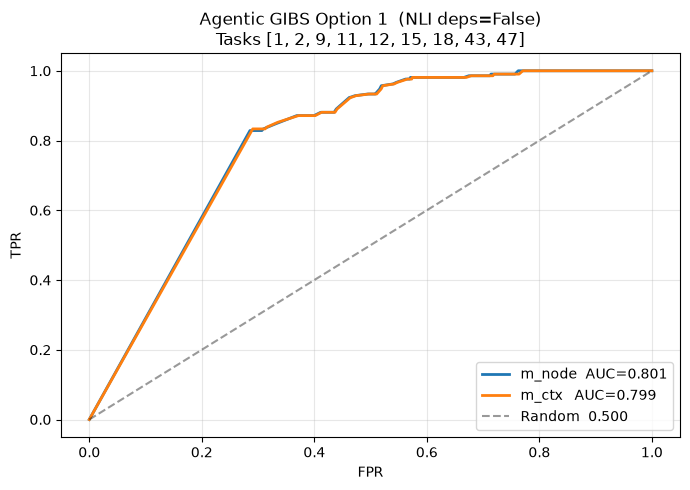

In [21]:
y_true, s_node, s_ctx = [], [], []
for row in annots:
    sd = all_consensus.get(row['run_id'], {}).get(int(row['step_idx']))
    if sd is None: continue
    y_true.append(1 if row['label'] in ('incorrect', 'tool_error') else 0)
    s_node.append(1 - sd['m_node'])
    s_ctx.append(1 - sd['m_ctx'])

auc_node = roc_auc_score(y_true, s_node)
auc_ctx  = roc_auc_score(y_true, s_ctx)
print(f"Steps matched : {len(y_true)}  (pos={sum(y_true)}, neg={len(y_true)-sum(y_true)})")
print(f"AUROC m_node  : {auc_node:.4f}")
print(f"AUROC m_ctx   : {auc_ctx:.4f}")
print(f"\nBaselines:")
print(f"  paper_literal NLI (Variant A) : ~0.723")
print(f"  tool_sim NIBS                 : ~0.982")

fig, ax = plt.subplots(figsize=(7, 5))
for sc, lbl in [(s_node, f'm_node  AUC={auc_node:.3f}'), (s_ctx, f'm_ctx   AUC={auc_ctx:.3f}')]:
    fpr, tpr, _ = roc_curve(y_true, sc)
    ax.plot(fpr, tpr, lw=2, label=lbl)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random  0.500')
ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.set_title(f'Agentic GIBS Option 1  (NLI deps={USE_NLI_DEPS})\nTasks {TASKS}')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(DRIVE_BASE + '/agentic_gibs_roc.png', dpi=150)
plt.show()

In [22]:
# ── NA-MCS Run ────────────────────────────────────────────────────────────────
def run_task_na(tid, pbar=None):
    task      = tasks_map[tid]
    all_sims  = sims_by_task.get(tid, [])
    pass_sims = [s for s in all_sims if (s.get('reward_info') or {}).get('reward', 0) >= 0.5]

    if len(pass_sims) < 2:
        if pbar: pbar.update(len(all_sims))
        return {}

    ref_graphs_na = {}
    for s in pass_sims:
        sg = build_step_graph(s, info, task)
        d  = get_deps(sg)
        ref_graphs_na[s['id']] = project_agentic_na(sg, d)

    results_na = {}
    for s in all_sims:
        sg    = build_step_graph(s, info, task)
        d     = get_deps(sg)
        qg_na = project_agentic_na(sg, d)
        refs  = {k: v for k, v in ref_graphs_na.items() if k != s['id']}
        if not refs:
            if pbar: pbar.update(1)
            continue

        mcs_res_na = [find_mcs_na(qg_na, rg, sim, MCS_CFG) for rg in refs.values()]
        masks_na   = consensus_masks(qg_na, mcs_res_na)

        step_scores = {}
        for idx, n in enumerate(sg['nodes']):
            if n['type'] != 'AgentStep': continue
            m = masks_na.get(n['id'], {})
            step_scores[idx] = {'m_node': m.get('m_node', 0.0), 'm_ctx': m.get('m_ctx', 0.0)}
        results_na[s['id']] = step_scores

        if pbar: pbar.update(1)

    return results_na

total_all = sum(len(sims_by_task.get(tid, [])) for tid in TASKS)
all_consensus_na = {}
with tqdm(total=total_all, desc='NA-MCS scoring', unit='run') as pbar:
    for tid in TASKS:
        pbar.set_postfix(task=tid)
        all_consensus_na.update(run_task_na(tid, pbar))

print(f'Total runs scored (NA-MCS): {len(all_consensus_na)}')

NA-MCS scoring:   0%|          | 0/180 [00:00<?, ?run/s]

Total runs scored (NA-MCS): 180


Steps matched  : 2857  (pos=210, neg=2647)
AUROC Option 1 : 0.8006
AUROC NA-MCS   : 0.8077


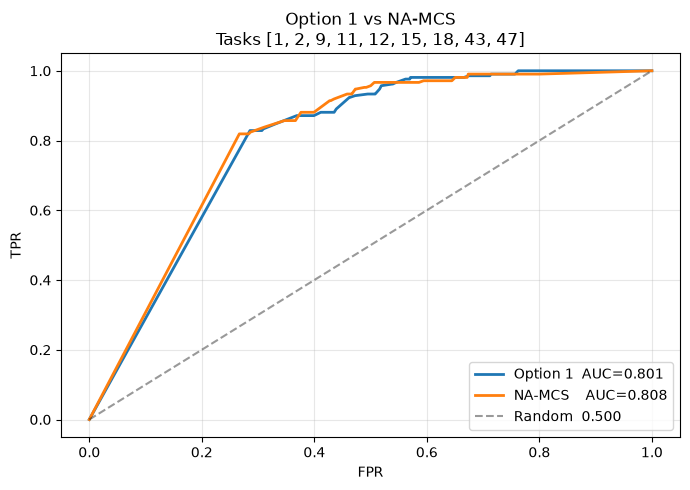

In [23]:
# ── AUROC Comparison: Option 1 vs NA-MCS ─────────────────────────────────────
y_true, s_opt1, s_na = [], [], []
for row in annots:
    sd1 = all_consensus.get(row['run_id'], {}).get(int(row['step_idx']))
    sd2 = all_consensus_na.get(row['run_id'], {}).get(int(row['step_idx']))
    if sd1 is None or sd2 is None:
        continue
    y_true.append(1 if row['label'] in ('incorrect', 'tool_error') else 0)
    s_opt1.append(1 - sd1['m_node'])
    s_na.append(1 - sd2['m_node'])

auc_opt1 = roc_auc_score(y_true, s_opt1)
auc_na   = roc_auc_score(y_true, s_na)

print(f"Steps matched  : {len(y_true)}  (pos={sum(y_true)}, neg={len(y_true)-sum(y_true)})")
print(f"AUROC Option 1 : {auc_opt1:.4f}")
print(f"AUROC NA-MCS   : {auc_na:.4f}")

fig, ax = plt.subplots(figsize=(7, 5))
for sc, lbl in [(s_opt1, f'Option 1  AUC={auc_opt1:.3f}'),
                (s_na,   f'NA-MCS    AUC={auc_na:.3f}')]:
    fpr, tpr, _ = roc_curve(y_true, sc)
    ax.plot(fpr, tpr, lw=2, label=lbl)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random  0.500')
ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.set_title(f'Option 1 vs NA-MCS\nTasks {TASKS}')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(DRIVE_BASE + '/comparison_roc.png', dpi=150)
plt.show()

## A\*-GED — Graph Edit Distance (Exact, Typed Edges)

**What:** Find the minimum-cost edit sequence to transform the query trajectory graph into the reference graph.

**Edit operations on nodes:**
| Operation | Cost |
|-----------|------|
| Substitute step qi → rj | `1 − NLI(op_text_q, op_text_r)` |
| Delete step qi (no match) | 0.5 |
| Insert step rj (extra in ref) | 0.5 |

**Edge costs — the graph-aware part:**
| Query edge | Ref edge | Cost | Meaning |
|-----------|---------|------|---------|
| data_dependency | data_dependency | 0.0 | dep chain intact |
| data_dependency | temporal | 0.3 | dep weakened |
| data_dependency | missing | 1.0 | dep chain broken |
| temporal | temporal | 0.0 | order intact |
| temporal | missing | 0.5 | ordering broken |

**A\* search:**
- State = partial assignment {q0→r2, q1→ε, q2→r0, ...}
- `g(n)` = cost so far (node subs/deletions + edge costs for assigned nodes)
- `h(n)` = 0.5 × remaining unmatched ref nodes ← admissible lower bound
- Expands ~500–2000 states for 20-step trajectories → exact optimal result

**Per-step score:**
`m_ged(step) = 1 − (node_cost + 0.5 × edge_cost)` averaged over all passing refs.
Error score = `1 − m_ged`

In [24]:
# ── A*-GED Implementation ─────────────────────────────────────────────────────
import heapq

C_NODE   = 0.5   # deletion / insertion cost per node
LAMBDA_E = 0.5   # edge cost weight in total score

EDGE_COSTS = {
    ('data_dependency', 'data_dependency'): 0.0,
    ('data_dependency', 'temporal'):        0.3,
    ('data_dependency', None):              1.0,
    ('temporal',        'temporal'):        0.0,
    ('temporal',        'data_dependency'): 0.3,
    ('temporal',        None):              0.5,
}


def _sg_to_ged(sg):
    """AgentStep nodes + inter-step edge dict {(i,j): type} from step graph."""
    nodes = [n for n in sg['nodes'] if n['type'] == 'AgentStep']
    idx   = {n['id']: i for i, n in enumerate(nodes)}
    ids   = set(idx)
    edges = {(idx[e['source']], idx[e['target']]): e['type']
             for e in sg['edges']
             if e['source'] in ids and e['target'] in ids}
    return nodes, edges


def _inc_ec(qi, ri, asgn_dict, eq, er):
    """Edge costs for edges incident to qi (matched to ri, -1=deleted),
    counting only edges whose other endpoint is already in asgn_dict."""
    cost = 0.0
    for (src, dst), tq in eq.items():
        if src != qi and dst != qi: continue
        qk = dst if src == qi else src
        if qk not in asgn_dict:     continue
        rk = asgn_dict[qk]
        if ri < 0 or rk < 0:
            tr = None
        else:
            r_src, r_dst = (ri, rk) if src == qi else (rk, ri)
            tr = er.get((r_src, r_dst))
        cost += EDGE_COSTS.get((tq, tr), 0.5)
    return cost


def astar_ged(sg_q, sg_r, sim_fn, max_states=8000):
    """
    Exact A* GED between two step graphs.
    Returns (node_costs, edge_costs) lists — one entry per AgentStep in sg_q.
    """
    nq_nodes, eq = _sg_to_ged(sg_q)
    nr_nodes, er = _sg_to_ged(sg_r)
    nq, nr = len(nq_nodes), len(nr_nodes)
    if nq == 0:
        return [], []

    # prefetch all NLI pairs upfront
    pairs = [(a['op_text'], b['op_text']) for a in nq_nodes for b in nr_nodes]
    sim_fn.prefetch(pairs + [(b, a) for a, b in pairs])

    # substitution cost matrix
    S = [[1.0 - sim_fn(nq_nodes[i]['op_text'], nr_nodes[j]['op_text'])
          for j in range(nr)] for i in range(nq)]

    # heap: (f, g, asgn_tuple, available_frozenset)
    heap = [(C_NODE * nr, 0.0, (), frozenset(range(nr)))]
    best_cost, best_asgn = float('inf'), None

    n_states = 0
    while heap and n_states < max_states:
        f, g, asgn, avail = heapq.heappop(heap)
        n_states += 1
        if f >= best_cost: continue

        qi = len(asgn)
        asgn_dict = dict(enumerate(asgn))

        if qi == nq:
            total = g + C_NODE * len(avail)
            if total < best_cost:
                best_cost, best_asgn = total, asgn
            continue

        # option A: delete qi
        ec = _inc_ec(qi, -1, asgn_dict, eq, er)
        g2 = g + C_NODE + LAMBDA_E * ec
        heapq.heappush(heap, (g2 + C_NODE * len(avail), g2, asgn + (-1,), avail))

        # option B: substitute qi → rj
        for j in avail:
            ec = _inc_ec(qi, j, asgn_dict, eq, er)
            g2 = g + S[qi][j] + LAMBDA_E * ec
            heapq.heappush(heap, (g2 + C_NODE * (len(avail)-1), g2, asgn + (j,), avail - {j}))

    if best_asgn is None:
        best_asgn = tuple([-1] * nq)

    # reconstruct per-step costs
    full = dict(enumerate(best_asgn))
    nc   = [min(S[i]) if best_asgn[i] < 0 else S[i][best_asgn[i]] for i in range(nq)]
    ec_l = [_inc_ec(i, best_asgn[i], {k: v for k, v in full.items() if k != i}, eq, er)
            for i in range(nq)]
    return nc, ec_l


print('A*-GED ready')

A*-GED ready


A*-GED scoring:   0%|          | 0/180 [00:00<?, ?run/s]

Total runs scored (A*-GED): 180
Steps matched  : 2857  (pos=210, neg=2647)
AUROC Option 1 : 0.8006
AUROC NA-MCS   : 0.8077
AUROC A*-GED   : 0.6789


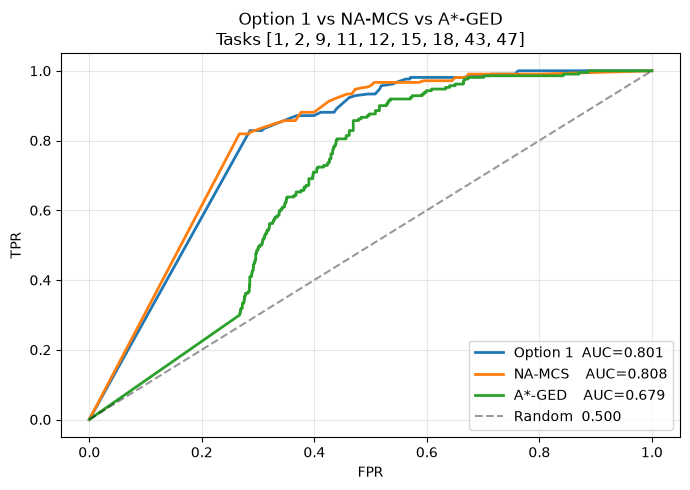

In [25]:
# ── A*-GED Run ────────────────────────────────────────────────────────────────
def run_task_ged(tid, pbar=None):
    task      = tasks_map[tid]
    all_sims  = sims_by_task.get(tid, [])
    pass_sims = [s for s in all_sims if (s.get('reward_info') or {}).get('reward', 0) >= 0.5]

    if len(pass_sims) < 2:
        if pbar: pbar.update(len(all_sims))
        return {}

    ref_sgs = {s['id']: build_step_graph(s, info, task) for s in pass_sims}

    results_ged = {}
    for s in all_sims:
        sg_q = build_step_graph(s, info, task)
        refs = {k: v for k, v in ref_sgs.items() if k != s['id']}
        if not refs:
            if pbar: pbar.update(1)
            continue

        nq_nodes = [n for n in sg_q['nodes'] if n['type'] == 'AgentStep']
        per_nc   = [[] for _ in nq_nodes]
        per_ec   = [[] for _ in nq_nodes]

        for sg_r in refs.values():
            nc, ec = astar_ged(sg_q, sg_r, sim)
            for i in range(len(nq_nodes)):
                if i < len(nc):
                    per_nc[i].append(nc[i])
                    per_ec[i].append(ec[i])

        step_scores = {}
        pos = 0
        for idx, n in enumerate(sg_q['nodes']):
            if n['type'] != 'AgentStep': continue
            avg_nc = np.mean(per_nc[pos]) if per_nc[pos] else 1.0
            avg_ec = np.mean(per_ec[pos]) if per_ec[pos] else 1.0
            m_ged  = max(0.0, min(1.0, 1.0 - avg_nc - LAMBDA_E * avg_ec))
            step_scores[idx] = {'m_ged': m_ged}
            pos += 1
        results_ged[s['id']] = step_scores

        if pbar: pbar.update(1)
    return results_ged


total_all = sum(len(sims_by_task.get(tid, [])) for tid in TASKS)
all_consensus_ged = {}
with tqdm(total=total_all, desc='A*-GED scoring', unit='run') as pbar:
    for tid in TASKS:
        pbar.set_postfix(task=tid)
        all_consensus_ged.update(run_task_ged(tid, pbar))

print(f'Total runs scored (A*-GED): {len(all_consensus_ged)}')

# ── 3-way AUROC comparison ────────────────────────────────────────────────────
y_true, s_opt1, s_na, s_ged = [], [], [], []
for row in annots:
    sd1 = all_consensus.get(row['run_id'], {}).get(int(row['step_idx']))
    sd2 = all_consensus_na.get(row['run_id'], {}).get(int(row['step_idx']))
    sd3 = all_consensus_ged.get(row['run_id'], {}).get(int(row['step_idx']))
    if sd1 is None or sd2 is None or sd3 is None: continue
    y_true.append(1 if row['label'] in ('incorrect', 'tool_error') else 0)
    s_opt1.append(1 - sd1['m_node'])
    s_na.append(1 - sd2['m_node'])
    s_ged.append(1 - sd3['m_ged'])

auc_opt1 = roc_auc_score(y_true, s_opt1)
auc_na   = roc_auc_score(y_true, s_na)
auc_ged  = roc_auc_score(y_true, s_ged)
print(f"Steps matched  : {len(y_true)}  (pos={sum(y_true)}, neg={len(y_true)-sum(y_true)})")
print(f"AUROC Option 1 : {auc_opt1:.4f}")
print(f"AUROC NA-MCS   : {auc_na:.4f}")
print(f"AUROC A*-GED   : {auc_ged:.4f}")

fig, ax = plt.subplots(figsize=(7, 5))
for sc, lbl in [(s_opt1, f'Option 1  AUC={auc_opt1:.3f}'),
                (s_na,   f'NA-MCS    AUC={auc_na:.3f}'),
                (s_ged,  f'A*-GED    AUC={auc_ged:.3f}')]:
    fpr, tpr, _ = roc_curve(y_true, sc)
    ax.plot(fpr, tpr, lw=2, label=lbl)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random  0.500')
ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.set_title(f'Option 1 vs NA-MCS vs A*-GED\nTasks {TASKS}')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(DRIVE_BASE + '/comparison_all_roc.png', dpi=150)
plt.show()

In [26]:
## Prefix-GED — Step-level Graph Edit Distance                                                                                    
"""   
**Problem with A\*-GED:** It aligns whole graphs globally, then extracts per-step costs post-hoc. A correct step can get a high   
cost just because the global assignment placed it in the wrong position.                                                        

**Fix — Prefix-GED:** For each step `i`, run A\*-GED on only the **window subgraph ending at step `i`** (last `window=5` steps).
The score for step `i` is the cost of the *last node* in that local alignment — not derived from a global assignment.

**Why this is step-level:**
- Each step gets its own dedicated GED computation
- The window captures local trajectory context (data deps + ordering)
- No future steps influence the current step's score

**Score:** `m_pged(i) = 1 − node_cost(i) − λ × edge_cost(i)` averaged over all pass references.
Error signal = `1 − m_pged`
"""

<>:3: SyntaxWarning: "\*" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\*"? A raw string is also an option.
<>:3: SyntaxWarning: "\*" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\*"? A raw string is also an option.
/tmp/ipykernel_1933472/3679673908.py:3: SyntaxWarning: "\*" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\*"? A raw string is also an option.
  **Problem with A\*-GED:** It aligns whole graphs globally, then extracts per-step costs post-hoc. A correct step can get a high


"   \n**Problem with A\\*-GED:** It aligns whole graphs globally, then extracts per-step costs post-hoc. A correct step can get a high   \ncost just because the global assignment placed it in the wrong position.                                                        \n\n**Fix — Prefix-GED:** For each step `i`, run A\\*-GED on only the **window subgraph ending at step `i`** (last `window=5` steps).\nThe score for step `i` is the cost of the *last node* in that local alignment — not derived from a global assignment.\n\n**Why this is step-level:**\n- Each step gets its own dedicated GED computation\n- The window captures local trajectory context (data deps + ordering)\n- No future steps influence the current step's score\n\n**Score:** `m_pged(i) = 1 − node_cost(i) − λ × edge_cost(i)` averaged over all pass references.\nError signal = `1 − m_pged`\n"

Prefix-GED scoring:   0%|          | 0/180 [00:00<?, ?run/s]

Total runs scored (Prefix-GED): 180
Steps matched    : 2857  (pos=210, neg=2647)
AUROC Option 1   : 0.8006
AUROC NA-MCS     : 0.8077
AUROC A*-GED     : 0.6789
AUROC Prefix-GED : 0.7457


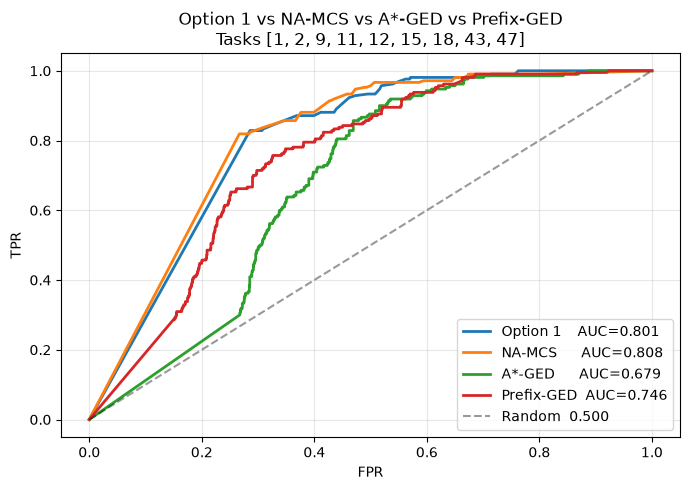

In [27]:
  # ── Prefix-GED: Step-level GED via sliding window subgraphs ──────────────────

  def astar_ged_nodes(nq_nodes, nr_nodes, eq, er, sim_fn, max_states=2000):
      """A*-GED on pre-extracted node/edge lists (reuses _inc_ec, C_NODE, LAMBDA_E)."""
      nq, nr = len(nq_nodes), len(nr_nodes)
      if nq == 0:
          return [], []
      pairs = [(a['op_text'], b['op_text']) for a in nq_nodes for b in nr_nodes]
      sim_fn.prefetch(pairs + [(b, a) for a, b in pairs])
      S = [[1.0 - sim_fn(nq_nodes[i]['op_text'], nr_nodes[j]['op_text'])
            for j in range(nr)] for i in range(nq)]
      heap = [(C_NODE * nr, 0.0, (), frozenset(range(nr)))]
      best_cost, best_asgn = float('inf'), None
      n_states = 0
      while heap and n_states < max_states:
          f, g, asgn, avail = heapq.heappop(heap)
          n_states += 1
          if f >= best_cost: continue
          qi = len(asgn)
          asgn_dict = dict(enumerate(asgn))
          if qi == nq:
              total = g + C_NODE * len(avail)
              if total < best_cost:
                  best_cost, best_asgn = total, asgn
              continue
          ec = _inc_ec(qi, -1, asgn_dict, eq, er)
          g2 = g + C_NODE + LAMBDA_E * ec
          heapq.heappush(heap, (g2 + C_NODE * len(avail), g2, asgn + (-1,), avail))
          for j in avail:
              ec = _inc_ec(qi, j, asgn_dict, eq, er)
              g2 = g + S[qi][j] + LAMBDA_E * ec
              heapq.heappush(heap, (g2 + C_NODE * (len(avail)-1), g2, asgn + (j,), avail - {j}))
      if best_asgn is None:
          best_asgn = tuple([-1] * nq)
      full = dict(enumerate(best_asgn))
      nc   = [min(S[i]) if best_asgn[i] < 0 else S[i][best_asgn[i]] for i in range(nq)]
      ec_l = [_inc_ec(i, best_asgn[i], {k: v for k, v in full.items() if k != i}, eq, er)
              for i in range(nq)]
      return nc, ec_l


  def run_task_prefix_ged(tid, pbar=None, window=5):
      """
      For each step i, run GED on a sliding window of the last `window` steps
      ending at i. Score = cost of the last node in that local alignment.
      """
      task      = tasks_map[tid]
      all_sims  = sims_by_task.get(tid, [])
      pass_sims = [s for s in all_sims if (s.get('reward_info') or {}).get('reward', 0) >= 0.5]
      if len(pass_sims) < 2:
          if pbar: pbar.update(len(all_sims))
          return {}

      ref_data = {}
      for s in pass_sims:
          sg = build_step_graph(s, info, task)
          ref_data[s['id']] = _sg_to_ged(sg)   # (nodes, edges)

      results = {}
      for s in all_sims:
          sg_q     = build_step_graph(s, info, task)
          nq_nodes, eq = _sg_to_ged(sg_q)
          refs = [(nodes, edges) for rid, (nodes, edges) in ref_data.items()
                  if rid != s['id']]
          if not refs:
              if pbar: pbar.update(1)
              continue

          step_scores = {}
          pos = 0
          for idx, n in enumerate(sg_q['nodes']):
              if n['type'] != 'AgentStep':
                  continue

              # sliding window [start..pos] inclusive
              start = max(0, pos - window + 1)
              end   = pos + 1
              nq_win = nq_nodes[start:end]
              eq_win = {(i - start, j - start): t
                        for (i, j), t in eq.items()
                        if start <= i < end and start <= j < end}

              per_nc_last, per_ec_last = [], []
              for nr_nodes, er in refs:
                  nr_win = nr_nodes[start:end]
                  er_win = {(i - start, j - start): t
                            for (i, j), t in er.items()
                            if start <= i < end and start <= j < end}
                  if not nr_win:
                      continue
                  nc, ec = astar_ged_nodes(nq_win, nr_win, eq_win, er_win,
                                           sim, max_states=1000)
                  if nc:
                      per_nc_last.append(nc[-1])   # cost of step `pos` only
                      per_ec_last.append(ec[-1])

              if per_nc_last:
                  avg_nc = np.mean(per_nc_last)
                  avg_ec = np.mean(per_ec_last)
                  m_pged = max(0.0, min(1.0, 1.0 - avg_nc - LAMBDA_E * avg_ec))
              else:
                  m_pged = 0.5
              step_scores[idx] = {'m_pged': m_pged}
              pos += 1

          results[s['id']] = step_scores
          if pbar: pbar.update(1)
      return results


  # ── Run ───────────────────────────────────────────────────────────────────────
  total_all = sum(len(sims_by_task.get(tid, [])) for tid in TASKS)
  all_consensus_pged = {}
  with tqdm(total=total_all, desc='Prefix-GED scoring', unit='run') as pbar:
      for tid in TASKS:
          pbar.set_postfix(task=tid)
          all_consensus_pged.update(run_task_prefix_ged(tid, pbar))

  print(f'Total runs scored (Prefix-GED): {len(all_consensus_pged)}')

  # ── 4-way AUROC ───────────────────────────────────────────────────────────────
  y_true, s_opt1, s_na, s_ged, s_pged = [], [], [], [], []
  for row in annots:
      sd1 = all_consensus.get(row['run_id'],      {}).get(int(row['step_idx']))
      sd2 = all_consensus_na.get(row['run_id'],   {}).get(int(row['step_idx']))
      sd3 = all_consensus_ged.get(row['run_id'],  {}).get(int(row['step_idx']))
      sd4 = all_consensus_pged.get(row['run_id'], {}).get(int(row['step_idx']))
      if any(x is None for x in [sd1, sd2, sd3, sd4]): continue
      y_true.append(1 if row['label'] in ('incorrect', 'tool_error') else 0)
      s_opt1.append(1 - sd1['m_node'])
      s_na.append(1 - sd2['m_node'])
      s_ged.append(1 - sd3['m_ged'])
      s_pged.append(1 - sd4['m_pged'])

  auc_opt1 = roc_auc_score(y_true, s_opt1)
  auc_na   = roc_auc_score(y_true, s_na)
  auc_ged  = roc_auc_score(y_true, s_ged)
  auc_pged = roc_auc_score(y_true, s_pged)

  print(f"Steps matched    : {len(y_true)}  (pos={sum(y_true)}, neg={len(y_true)-sum(y_true)})")
  print(f"AUROC Option 1   : {auc_opt1:.4f}")
  print(f"AUROC NA-MCS     : {auc_na:.4f}")
  print(f"AUROC A*-GED     : {auc_ged:.4f}")
  print(f"AUROC Prefix-GED : {auc_pged:.4f}")

  fig, ax = plt.subplots(figsize=(7, 5))
  for sc, lbl in [(s_opt1, f'Option 1    AUC={auc_opt1:.3f}'),
                  (s_na,   f'NA-MCS      AUC={auc_na:.3f}'),
                  (s_ged,  f'A*-GED      AUC={auc_ged:.3f}'),
                  (s_pged, f'Prefix-GED  AUC={auc_pged:.3f}')]:
      fpr, tpr, _ = roc_curve(y_true, sc)
      ax.plot(fpr, tpr, lw=2, label=lbl)
  ax.plot([0,1],[0,1], 'k--', alpha=0.4, label='Random  0.500')
  ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
  ax.set_title(f'Option 1 vs NA-MCS vs A*-GED vs Prefix-GED\nTasks {TASKS}')
  ax.legend(); ax.grid(alpha=0.3)
  plt.tight_layout()
  plt.savefig(DRIVE_BASE + '/comparison_pged_roc.png', dpi=150)
  plt.show()

In [28]:
                                                                                                                                                                                                    
  # ── Option C: GED with min-NLI node scoring (decouple node score from alignment) ──
                                                                                                                                                                                                    
  def astar_ged_optC(sg_q, sg_r, sim_fn, max_states=8000):
      """Same as astar_ged but nc[i] = min(S[i]) for ALL steps (not just deleted)."""
      nq_nodes, eq = _sg_to_ged(sg_q)
      nr_nodes, er = _sg_to_ged(sg_r)
      nq, nr = len(nq_nodes), len(nr_nodes)
      if nq == 0:
          return [], []

      pairs = [(a['op_text'], b['op_text']) for a in nq_nodes for b in nr_nodes]
      sim_fn.prefetch(pairs + [(b, a) for a, b in pairs])
      S = [[1.0 - sim_fn(nq_nodes[i]['op_text'], nr_nodes[j]['op_text'])
            for j in range(nr)] for i in range(nq)]

      heap = [(C_NODE * nr, 0.0, (), frozenset(range(nr)))]
      best_cost, best_asgn = float('inf'), None
      n_states = 0
      while heap and n_states < max_states:
          f, g, asgn, avail = heapq.heappop(heap)
          n_states += 1
          if f >= best_cost: continue
          qi = len(asgn)
          asgn_dict = dict(enumerate(asgn))
          if qi == nq:
              total = g + C_NODE * len(avail)
              if total < best_cost:
                  best_cost, best_asgn = total, asgn
              continue
          ec = _inc_ec(qi, -1, asgn_dict, eq, er)
          g2 = g + C_NODE + LAMBDA_E * ec
          heapq.heappush(heap, (g2 + C_NODE * len(avail), g2, asgn + (-1,), avail))
          for j in avail:
              ec = _inc_ec(qi, j, asgn_dict, eq, er)
              g2 = g + S[qi][j] + LAMBDA_E * ec
              heapq.heappush(heap, (g2 + C_NODE * (len(avail)-1), g2, asgn + (j,), avail - {j}))

      if best_asgn is None:
          best_asgn = tuple([-1] * nq)

      # Option C: node score = best NLI match regardless of alignment
      full = dict(enumerate(best_asgn))
      nc   = [min(S[i]) for i in range(nq)]   # <-- only change from astar_ged
      ec_l = [_inc_ec(i, best_asgn[i], {k: v for k, v in full.items() if k != i}, eq, er)
              for i in range(nq)]
      return nc, ec_l


  def run_task_ged_optC(tid, pbar=None):
      task      = tasks_map[tid]
      all_sims  = sims_by_task.get(tid, [])
      pass_sims = [s for s in all_sims if (s.get('reward_info') or {}).get('reward', 0) >= 0.5]
      if len(pass_sims) < 2:
          if pbar: pbar.update(len(all_sims))
          return {}
      ref_sgs = {s['id']: build_step_graph(s, info, task) for s in pass_sims}
      results = {}
      for s in all_sims:
          sg_q = build_step_graph(s, info, task)
          refs = {k: v for k, v in ref_sgs.items() if k != s['id']}
          if not refs:
              if pbar: pbar.update(1); continue
          nq_nodes = [n for n in sg_q['nodes'] if n['type'] == 'AgentStep']
          per_nc = [[] for _ in nq_nodes]
          per_ec = [[] for _ in nq_nodes]
          for sg_r in refs.values():
              nc, ec = astar_ged_optC(sg_q, sg_r, sim)
              for i in range(len(nq_nodes)):
                  if i < len(nc):
                      per_nc[i].append(nc[i]); per_ec[i].append(ec[i])
          step_scores = {}
          pos = 0
          for idx, n in enumerate(sg_q['nodes']):
              if n['type'] != 'AgentStep': continue
              avg_nc = np.mean(per_nc[pos]) if per_nc[pos] else 1.0
              avg_ec = np.mean(per_ec[pos]) if per_ec[pos] else 1.0
              step_scores[idx] = {'m_ged_c': max(0.0, min(1.0, 1.0 - avg_nc - LAMBDA_E * avg_ec))}
              pos += 1
          results[s['id']] = step_scores
          if pbar: pbar.update(1)
      return results


  total_all = sum(len(sims_by_task.get(tid, [])) for tid in TASKS)
  all_consensus_ged_c = {}
  with tqdm(total=total_all, desc='A*-GED Option C', unit='run') as pbar:
      for tid in TASKS:
          pbar.set_postfix(task=tid)
          all_consensus_ged_c.update(run_task_ged_optC(tid, pbar))

  # 5-way AUROC
  y_true, s_opt1, s_na, s_ged, s_pged, s_gedc = [], [], [], [], [], []
  for row in annots:
      sd1 = all_consensus.get(row['run_id'],      {}).get(int(row['step_idx']))
      sd2 = all_consensus_na.get(row['run_id'],   {}).get(int(row['step_idx']))
      sd3 = all_consensus_ged.get(row['run_id'],  {}).get(int(row['step_idx']))
      sd4 = all_consensus_pged.get(row['run_id'], {}).get(int(row['step_idx']))
      sd5 = all_consensus_ged_c.get(row['run_id'],{}).get(int(row['step_idx']))
      if any(x is None for x in [sd1,sd2,sd3,sd4,sd5]): continue
      y_true.append(1 if row['label'] in ('incorrect','tool_error') else 0)
      s_opt1.append(1 - sd1['m_node'])
      s_na.append(1 - sd2['m_node'])
      s_ged.append(1 - sd3['m_ged'])
      s_pged.append(1 - sd4['m_pged'])
      s_gedc.append(1 - sd5['m_ged_c'])

  print(f"Steps matched    : {len(y_true)}  (pos={sum(y_true)}, neg={len(y_true)-sum(y_true)})")
  print(f"AUROC Option 1   : {roc_auc_score(y_true, s_opt1):.4f}")
  print(f"AUROC NA-MCS     : {roc_auc_score(y_true, s_na):.4f}")
  print(f"AUROC A*-GED     : {roc_auc_score(y_true, s_ged):.4f}")
  print(f"AUROC Prefix-GED : {roc_auc_score(y_true, s_pged):.4f}")
  print(f"AUROC GED-OptC   : {roc_auc_score(y_true, s_gedc):.4f}")

A*-GED Option C:   0%|          | 0/180 [00:00<?, ?run/s]

Steps matched    : 2857  (pos=210, neg=2647)
AUROC Option 1   : 0.8006
AUROC NA-MCS     : 0.8077
AUROC A*-GED     : 0.6789
AUROC Prefix-GED : 0.7457
AUROC GED-OptC   : 0.6416


In [29]:
  # ── NA-GED: Neighborhood-Aware A*-GED ─────────────────────────────────────────
  # Same as A*-GED but substitution cost = α·NLI(step_i, step_j) + (1-α)·avg NLI(neighbors_i, neighbors_j)                                                                                          
  # Mirrors what NA-MCS does over MCS. Uses Option A scoring (deleted → min(S[i])).
                                                                                                                                                                                                    
  NA_ALPHA = 0.7   # weight: direct step similarity vs neighbor similarity

  def _nbr_texts(idx, nodes, edges):
      """op_text of AgentStep neighbors of node idx (undirected)."""
      nbrs = set()
      for (src, dst) in edges:
          if src == idx: nbrs.add(dst)
          if dst == idx: nbrs.add(src)
      return [nodes[k]['op_text'] for k in sorted(nbrs)
              if k < len(nodes) and nodes[k].get('op_text')]


  def astar_ged_na(sg_q, sg_r, sim_fn, max_states=8000):
      nq_nodes, eq = _sg_to_ged(sg_q)
      nr_nodes, er = _sg_to_ged(sg_r)
      nq, nr = len(nq_nodes), len(nr_nodes)
      if nq == 0:
          return [], []

      q_nbrs_all = [_nbr_texts(i, nq_nodes, eq) for i in range(nq)]
      r_nbrs_all = [_nbr_texts(j, nr_nodes, er) for j in range(nr)]

      # Prefetch direct + neighbor NLI pairs
      pairs = [(a['op_text'], b['op_text']) for a in nq_nodes for b in nr_nodes]
      for i in range(nq):
          for j in range(nr):
              pairs += [(qn, rn) for qn in q_nbrs_all[i] for rn in r_nbrs_all[j]]
      uniq = list(set(pairs))
      sim_fn.prefetch(uniq + [(b, a) for a, b in uniq])

      # Neighborhood-aware substitution cost matrix
      S = []
      for i in range(nq):
          row = []
          for j in range(nr):
              direct = sim_fn(nq_nodes[i]['op_text'], nr_nodes[j]['op_text'])
              qn, rn = q_nbrs_all[i], r_nbrs_all[j]
              nbr_sim = float(np.mean([sim_fn(a, b) for a in qn for b in rn])) if qn and rn else direct
              row.append(1.0 - (NA_ALPHA * direct + (1 - NA_ALPHA) * nbr_sim))
          S.append(row)

      # A* search (identical to astar_ged)
      heap = [(C_NODE * nr, 0.0, (), frozenset(range(nr)))]
      best_cost, best_asgn = float('inf'), None
      n_states = 0
      while heap and n_states < max_states:
          f, g, asgn, avail = heapq.heappop(heap)
          n_states += 1
          if f >= best_cost: continue
          qi = len(asgn)
          asgn_dict = dict(enumerate(asgn))
          if qi == nq:
              total = g + C_NODE * len(avail)
              if total < best_cost:
                  best_cost, best_asgn = total, asgn
              continue
          ec = _inc_ec(qi, -1, asgn_dict, eq, er)
          g2 = g + C_NODE + LAMBDA_E * ec
          heapq.heappush(heap, (g2 + C_NODE * len(avail), g2, asgn + (-1,), avail))
          for j in avail:
              ec = _inc_ec(qi, j, asgn_dict, eq, er)
              g2 = g + S[qi][j] + LAMBDA_E * ec
              heapq.heappush(heap, (g2 + C_NODE * (len(avail)-1), g2, asgn + (j,), avail - {j}))

      if best_asgn is None:
          best_asgn = tuple([-1] * nq)

      # Option A scoring: deleted step → min(S[i]) not C_NODE
      full = dict(enumerate(best_asgn))
      nc   = [min(S[i]) if best_asgn[i] < 0 else S[i][best_asgn[i]] for i in range(nq)]
      ec_l = [_inc_ec(i, best_asgn[i], {k: v for k, v in full.items() if k != i}, eq, er)
              for i in range(nq)]
      return nc, ec_l


  def run_task_ged_na(tid, pbar=None):
      task      = tasks_map[tid]
      all_sims  = sims_by_task.get(tid, [])
      pass_sims = [s for s in all_sims if (s.get('reward_info') or {}).get('reward', 0) >= 0.5]
      if len(pass_sims) < 2:
          if pbar: pbar.update(len(all_sims))
          return {}
      ref_sgs = {s['id']: build_step_graph(s, info, task) for s in pass_sims}
      results = {}
      for s in all_sims:
          sg_q = build_step_graph(s, info, task)
          refs = {k: v for k, v in ref_sgs.items() if k != s['id']}
          if not refs:
              if pbar: pbar.update(1); continue
          nq_nodes = [n for n in sg_q['nodes'] if n['type'] == 'AgentStep']
          per_nc = [[] for _ in nq_nodes]
          per_ec = [[] for _ in nq_nodes]
          for sg_r in refs.values():
              nc, ec = astar_ged_na(sg_q, sg_r, sim)
              for i in range(len(nq_nodes)):
                  if i < len(nc):
                      per_nc[i].append(nc[i]); per_ec[i].append(ec[i])
          step_scores = {}
          pos = 0
          for idx, n in enumerate(sg_q['nodes']):
              if n['type'] != 'AgentStep': continue
              avg_nc = np.mean(per_nc[pos]) if per_nc[pos] else 1.0
              avg_ec = np.mean(per_ec[pos]) if per_ec[pos] else 1.0
              step_scores[idx] = {'m_na_ged': max(0.0, min(1.0, 1.0 - avg_nc - LAMBDA_E * avg_ec))}
              pos += 1
          results[s['id']] = step_scores
          if pbar: pbar.update(1)
      return results


  total_all = sum(len(sims_by_task.get(tid, [])) for tid in TASKS)
  all_consensus_na_ged = {}
  with tqdm(total=total_all, desc='NA-GED scoring', unit='run') as pbar:
      for tid in TASKS:
          pbar.set_postfix(task=tid)
          all_consensus_na_ged.update(run_task_ged_na(tid, pbar))

  print(f'Total runs scored (NA-GED): {len(all_consensus_na_ged)}')

  # 5-way AUROC
  y_true, s_opt1, s_na, s_ged, s_pged, s_naged = [], [], [], [], [], []
  for row in annots:
      sd1 = all_consensus.get(row['run_id'],        {}).get(int(row['step_idx']))
      sd2 = all_consensus_na.get(row['run_id'],     {}).get(int(row['step_idx']))
      sd3 = all_consensus_ged.get(row['run_id'],    {}).get(int(row['step_idx']))
      sd4 = all_consensus_pged.get(row['run_id'],   {}).get(int(row['step_idx']))
      sd5 = all_consensus_na_ged.get(row['run_id'], {}).get(int(row['step_idx']))
      if any(x is None for x in [sd1,sd2,sd3,sd4,sd5]): continue
      y_true.append(1 if row['label'] in ('incorrect','tool_error') else 0)
      s_opt1.append(1 - sd1['m_node'])
      s_na.append(1 - sd2['m_node'])
      s_ged.append(1 - sd3['m_ged'])
      s_pged.append(1 - sd4['m_pged'])
      s_naged.append(1 - sd5['m_na_ged'])

  auc_opt1  = roc_auc_score(y_true, s_opt1)
  auc_na    = roc_auc_score(y_true, s_na)
  auc_ged   = roc_auc_score(y_true, s_ged)
  auc_pged  = roc_auc_score(y_true, s_pged)
  auc_naged = roc_auc_score(y_true, s_naged)

  print(f"Steps matched    : {len(y_true)}  (pos={sum(y_true)}, neg={len(y_true)-sum(y_true)})")
  print(f"AUROC Option 1   : {auc_opt1:.4f}")
  print(f"AUROC NA-MCS     : {auc_na:.4f}")
  print(f"AUROC A*-GED     : {auc_ged:.4f}")
  print(f"AUROC Prefix-GED : {auc_pged:.4f}")
  print(f"AUROC NA-GED     : {auc_naged:.4f}")

  fig, ax = plt.subplots(figsize=(7, 5))
  for sc, lbl in [(s_opt1,  f'Option 1    AUC={auc_opt1:.3f}'),
                  (s_na,    f'NA-MCS      AUC={auc_na:.3f}'),
                  (s_ged,   f'A*-GED      AUC={auc_ged:.3f}'),
                  (s_pged,  f'Prefix-GED  AUC={auc_pged:.3f}'),
                  (s_naged, f'NA-GED      AUC={auc_naged:.3f}')]:
      fpr, tpr, _ = roc_curve(y_true, sc)
      ax.plot(fpr, tpr, lw=2, label=lbl)
  ax.plot([0,1],[0,1],'k--',alpha=0.4,label='Random  0.500')
  ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
  ax.set_title(f'NA-GED vs All Methods\nTasks {TASKS}')
  ax.legend(); ax.grid(alpha=0.3)
  plt.tight_layout()
  plt.savefig(DRIVE_BASE + '/comparison_naged_roc.png', dpi=150)
  plt.show()

NA-GED scoring:   0%|          | 0/180 [00:00<?, ?run/s]

KeyboardInterrupt: 

In [ ]:
  # ── NA-Prefix-GED: Neighborhood-Aware Prefix-GED ──────────────────────────────                                                                                                                  
  # Prefix-GED (local window) + neighborhood-aware substitution costs (like NA-MCS)                                                                                                                 
                                                                                                                                                                                                    
  NA_PGED_ALPHA = 0.7                                                                                                                                                                               
                                                                                                                                                                                                    
  def _nbr_texts_win(idx, nodes, edges):                                                                                                                                                            
      """op_text of neighbors of idx using window-local edge dict."""                                                                                                                               
      nbrs = set()                                                                                                                                                                                  
      for (src, dst) in edges:                                                                                                                                                                      
          if src == idx: nbrs.add(dst)                                                                                                                                                              
          if dst == idx: nbrs.add(src)                                                                                                                                                              
      return [nodes[k]['op_text'] for k in sorted(nbrs)
              if k < len(nodes) and nodes[k].get('op_text')]


  def astar_ged_nodes_na(nq_nodes, nr_nodes, eq, er, sim_fn, max_states=1000):
      """Prefix-GED inner function with neighborhood-aware substitution costs."""
      nq, nr = len(nq_nodes), len(nr_nodes)
      if nq == 0:
          return [], []

      q_nbrs = [_nbr_texts_win(i, nq_nodes, eq) for i in range(nq)]
      r_nbrs = [_nbr_texts_win(j, nr_nodes, er) for j in range(nr)]

      pairs = [(a['op_text'], b['op_text']) for a in nq_nodes for b in nr_nodes]
      for i in range(nq):
          for j in range(nr):
              pairs += [(qn, rn) for qn in q_nbrs[i] for rn in r_nbrs[j]]
      uniq = list(set(pairs))
      sim_fn.prefetch(uniq + [(b, a) for a, b in uniq])

      S = []
      for i in range(nq):
          row = []
          for j in range(nr):
              direct = sim_fn(nq_nodes[i]['op_text'], nr_nodes[j]['op_text'])
              qn, rn = q_nbrs[i], r_nbrs[j]
              nbr_sim = float(np.mean([sim_fn(a, b) for a in qn for b in rn])) if qn and rn else direct
              row.append(1.0 - (NA_PGED_ALPHA * direct + (1 - NA_PGED_ALPHA) * nbr_sim))
          S.append(row)

      heap = [(C_NODE * nr, 0.0, (), frozenset(range(nr)))]
      best_cost, best_asgn = float('inf'), None
      n_states = 0
      while heap and n_states < max_states:
          f, g, asgn, avail = heapq.heappop(heap)
          n_states += 1
          if f >= best_cost: continue
          qi = len(asgn)
          asgn_dict = dict(enumerate(asgn))
          if qi == nq:
              total = g + C_NODE * len(avail)
              if total < best_cost:
                  best_cost, best_asgn = total, asgn
              continue
          ec = _inc_ec(qi, -1, asgn_dict, eq, er)
          g2 = g + C_NODE + LAMBDA_E * ec
          heapq.heappush(heap, (g2 + C_NODE * len(avail), g2, asgn + (-1,), avail))
          for j in avail:
              ec = _inc_ec(qi, j, asgn_dict, eq, er)
              g2 = g + S[qi][j] + LAMBDA_E * ec
              heapq.heappush(heap, (g2 + C_NODE * (len(avail)-1), g2, asgn + (j,), avail - {j}))

      if best_asgn is None:
          best_asgn = tuple([-1] * nq)

      # Option A scoring
      full = dict(enumerate(best_asgn))
      nc   = [min(S[i]) if best_asgn[i] < 0 else S[i][best_asgn[i]] for i in range(nq)]
      ec_l = [_inc_ec(i, best_asgn[i], {k: v for k, v in full.items() if k != i}, eq, er)
              for i in range(nq)]
      return nc, ec_l


  def run_task_na_prefix_ged(tid, pbar=None, window=5):
      task      = tasks_map[tid]
      all_sims  = sims_by_task.get(tid, [])
      pass_sims = [s for s in all_sims if (s.get('reward_info') or {}).get('reward', 0) >= 0.5]
      if len(pass_sims) < 2:
          if pbar: pbar.update(len(all_sims))
          return {}

      ref_data = {}
      for s in pass_sims:
          sg = build_step_graph(s, info, task)
          ref_data[s['id']] = _sg_to_ged(sg)

      results = {}
      for s in all_sims:
          sg_q         = build_step_graph(s, info, task)
          nq_nodes, eq = _sg_to_ged(sg_q)
          refs = [(nodes, edges) for rid, (nodes, edges) in ref_data.items()
                  if rid != s['id']]
          if not refs:
              if pbar: pbar.update(1); continue

          step_scores = {}
          pos = 0
          for idx, n in enumerate(sg_q['nodes']):
              if n['type'] != 'AgentStep': continue
              start  = max(0, pos - window + 1)
              end    = pos + 1
              nq_win = nq_nodes[start:end]
              eq_win = {(i - start, j - start): t
                        for (i, j), t in eq.items()
                        if start <= i < end and start <= j < end}
              per_nc_last, per_ec_last = [], []
              for nr_nodes, er in refs:
                  nr_win = nr_nodes[start:end]
                  er_win = {(i - start, j - start): t
                            for (i, j), t in er.items()
                            if start <= i < end and start <= j < end}
                  if not nr_win: continue
                  nc, ec = astar_ged_nodes_na(nq_win, nr_win, eq_win, er_win,
                                               sim, max_states=1000)
                  if nc:
                      per_nc_last.append(nc[-1])
                      per_ec_last.append(ec[-1])
              if per_nc_last:
                  avg_nc = np.mean(per_nc_last)
                  avg_ec = np.mean(per_ec_last)
                  m_na_pged = max(0.0, min(1.0, 1.0 - avg_nc - LAMBDA_E * avg_ec))
              else:
                  m_na_pged = 0.5
              step_scores[idx] = {'m_na_pged': m_na_pged}
              pos += 1

          results[s['id']] = step_scores
          if pbar: pbar.update(1)
      return results


  total_all = sum(len(sims_by_task.get(tid, [])) for tid in TASKS)
  all_consensus_na_pged = {}
  with tqdm(total=total_all, desc='NA-Prefix-GED scoring', unit='run') as pbar:
      for tid in TASKS:
          pbar.set_postfix(task=tid)
          all_consensus_na_pged.update(run_task_na_prefix_ged(tid, pbar))

  print(f'Total runs scored (NA-Prefix-GED): {len(all_consensus_na_pged)}')

  # 6-way AUROC
  y_true, s_opt1, s_na, s_ged, s_pged, s_naged, s_napged = [], [], [], [], [], [], []
  for row in annots:
      sd1 = all_consensus.get(row['run_id'],          {}).get(int(row['step_idx']))
      sd2 = all_consensus_na.get(row['run_id'],       {}).get(int(row['step_idx']))
      sd3 = all_consensus_ged.get(row['run_id'],      {}).get(int(row['step_idx']))
      sd4 = all_consensus_pged.get(row['run_id'],     {}).get(int(row['step_idx']))
      sd5 = all_consensus_na_ged.get(row['run_id'],   {}).get(int(row['step_idx']))
      sd6 = all_consensus_na_pged.get(row['run_id'],  {}).get(int(row['step_idx']))
      if any(x is None for x in [sd1,sd2,sd3,sd4,sd5,sd6]): continue
      y_true.append(1 if row['label'] in ('incorrect','tool_error') else 0)
      s_opt1.append(1 - sd1['m_node'])
      s_na.append(1 - sd2['m_node'])
      s_ged.append(1 - sd3['m_ged'])
      s_pged.append(1 - sd4['m_pged'])
      s_naged.append(1 - sd5['m_na_ged'])
      s_napged.append(1 - sd6['m_na_pged'])

  auc_opt1   = roc_auc_score(y_true, s_opt1)
  auc_na     = roc_auc_score(y_true, s_na)
  auc_ged    = roc_auc_score(y_true, s_ged)
  auc_pged   = roc_auc_score(y_true, s_pged)
  auc_naged  = roc_auc_score(y_true, s_naged)
  auc_napged = roc_auc_score(y_true, s_napged)

  print(f"Steps matched      : {len(y_true)}  (pos={sum(y_true)}, neg={len(y_true)-sum(y_true)})")
  print(f"AUROC Option 1     : {auc_opt1:.4f}")
  print(f"AUROC NA-MCS       : {auc_na:.4f}")
  print(f"AUROC A*-GED       : {auc_ged:.4f}")
  print(f"AUROC Prefix-GED   : {auc_pged:.4f}")
  print(f"AUROC NA-GED       : {auc_naged:.4f}")
  print(f"AUROC NA-Prefix-GED: {auc_napged:.4f}")

  fig, ax = plt.subplots(figsize=(7, 5))
  for sc, lbl in [(s_opt1,   f'Option 1       AUC={auc_opt1:.3f}'),
                  (s_na,     f'NA-MCS         AUC={auc_na:.3f}'),
                  (s_ged,    f'A*-GED         AUC={auc_ged:.3f}'),
                  (s_pged,   f'Prefix-GED     AUC={auc_pged:.3f}'),
                  (s_napged, f'NA-Prefix-GED  AUC={auc_napged:.3f}')]:
      fpr, tpr, _ = roc_curve(y_true, sc)
      ax.plot(fpr, tpr, lw=2, label=lbl)
  ax.plot([0,1],[0,1],'k--',alpha=0.4,label='Random  0.500')
  ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
  ax.set_title(f'NA-Prefix-GED vs All Methods\nTasks {TASKS}')
  ax.legend(); ax.grid(alpha=0.3)
  plt.tight_layout()
  plt.savefig(DRIVE_BASE + '/comparison_na_pged_roc.png', dpi=150)
  plt.show()

In [ ]:
  # ── Ensemble: Prefix-GED + Option 1 linear combination ───────────────────────
  alphas = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]                                                                                                                                  
   
  print("Alpha  | AUROC")                                                                                                                                                                           
  print("-------|-------")
  best_auc, best_alpha = 0, 0
  for alpha in alphas:
      s_ens = [alpha * s1 + (1 - alpha) * sp for s1, sp in zip(s_opt1, s_pged)]
      auc = roc_auc_score(y_true, s_ens)
      print(f"  {alpha:.1f}  | {auc:.4f}")
      if auc > best_auc:
          best_auc, best_alpha = auc, alpha

  print(f"\nBest: alpha={best_alpha:.1f}  AUROC={best_auc:.4f}")
  print(f"vs NA-MCS: 0.8101  vs Option 1: 0.8006")

In [ ]:
  # ── Fine-tune alpha + multi-way ensembles ─────────────────────────────────────                                                                                                                  
  from itertools import product                                                                                                                                                                     
   
  # 1. Fine-tune around alpha=0.9                                                                                                                                                                   
  print("=== Fine-tuned Option1 + Prefix-GED ===")
  for alpha in [0.85, 0.87, 0.88, 0.89, 0.90, 0.91, 0.92, 0.93, 0.95]:                                                                                                                              
      auc = roc_auc_score(y_true, [alpha*s1 + (1-alpha)*sp for s1,sp in zip(s_opt1, s_pged)])
      print(f"  alpha={alpha:.2f} | {auc:.4f}")

  # 2. NA-MCS + Prefix-GED
  print("\n=== NA-MCS + Prefix-GED ===")
  best2, best2_a = 0, 0
  for alpha in [0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]:
      auc = roc_auc_score(y_true, [alpha*s2 + (1-alpha)*sp for s2,sp in zip(s_na, s_pged)])
      print(f"  alpha={alpha:.1f} | {auc:.4f}")
      if auc > best2: best2, best2_a = auc, alpha
  print(f"  Best: alpha={best2_a:.1f}  AUROC={best2:.4f}")

  # 3. 3-way: a*Option1 + b*NA-MCS + (1-a-b)*Prefix-GED
  print("\n=== 3-way: Option1 + NA-MCS + Prefix-GED ===")
  best3, best3_ab = 0, (0,0)
  for a in [i/10 for i in range(11)]:
      for b in [i/10 for i in range(11)]:
          if a + b > 1.0: continue
          s_ens = [a*s1 + b*s2 + (1-a-b)*sp for s1,s2,sp in zip(s_opt1, s_na, s_pged)]
          auc = roc_auc_score(y_true, s_ens)
          if auc > best3:
              best3, best3_ab = auc, (a, b)

  a, b = best3_ab
  print(f"  Best: a(Opt1)={a:.1f}  b(NA-MCS)={b:.1f}  c(PrefGED)={1-a-b:.1f}")
  print(f"  AUROC={best3:.4f}")

  # Summary
  print("\n=== Summary ===")
  print(f"  NA-MCS                    : 0.8101")
  print(f"  Option1 + PrefGED (a=0.9) : 0.8378")
  best_fine = max(roc_auc_score(y_true, [a*s1+(1-a)*sp for s1,sp in zip(s_opt1,s_pged)])
                  for a in [0.85,0.87,0.88,0.89,0.90,0.91,0.92,0.93,0.95])
  print(f"  Option1 + PrefGED (fine)  : {best_fine:.4f}")
  print(f"  NA-MCS  + PrefGED (best)  : {best2:.4f}")
  print(f"  3-way ensemble (best)     : {best3:.4f}")

In [ ]:
  print("=== Fine-tuned 3-way ===")
  best, best_abc = 0, (0,0,0)                                                                                                                                                                       
  for a in [i*0.05 for i in range(21)]:
      for b in [i*0.05 for i in range(21)]:                                                                                                                                                         
          if a + b > 1.0: continue
          c = round(1 - a - b, 2)
          s_ens = [a*s1 + b*s2 + c*sp for s1,s2,sp in zip(s_opt1, s_na, s_pged)]
          auc = roc_auc_score(y_true, s_ens)
          if auc > best:
              best, best_abc = auc, (a, b, c)

  a, b, c = best_abc
  print(f"  Best: Opt1={a:.2f}  NA-MCS={b:.2f}  PrefGED={c:.2f}")
  print(f"  AUROC={best:.4f}")

Causal Prefix scoring:   0%|          | 0/180 [00:00<?, ?run/s]

Total runs scored (Causal Prefix): 180
Steps matched       : 2857  (pos=210, neg=2647)
AUROC Option 1      : 0.8006
AUROC NA-MCS        : 0.8077
AUROC Prefix-GED    : 0.7457
AUROC Causal Prefix : 0.7709


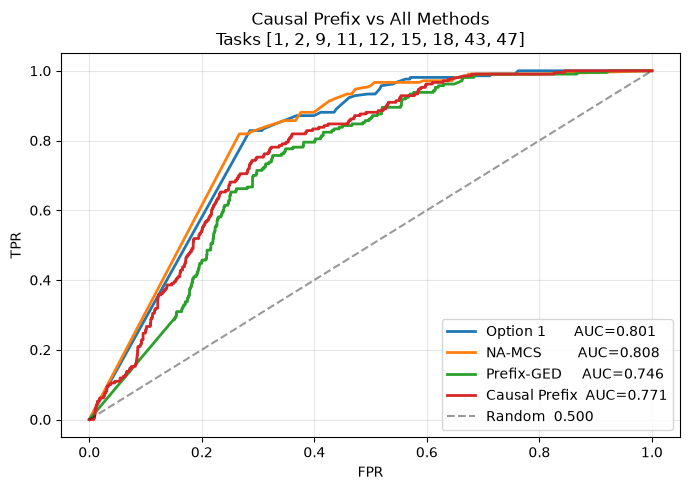

In [36]:
                                                                                                                                                                               
  # ── Causal Prefix Score: history-weighted step-level NLI scoring ───────────────                                                                                                                 
  # Inspired by Trajectory Guard (arXiv:2601.00516).                                                                                                                                                
  # For step i: weight each reference by how well it matched steps 0..i-1,                                                                                                                          
  # then score step i as weighted-average NLI match to position i in references.                                                                                                                    
  # References that diverged early get low weight → their step i score ignored.                                                                                                                     
  # An incorrect step in an otherwise-correct trajectory → low score → high anomaly.                                                                                                                
                                                                                                                                                                                                    
  def run_task_causal_prefix(tid, pbar=None):                                                                                                                                                       
      task      = tasks_map[tid]                                                                                                                                                                    
      all_sims  = sims_by_task.get(tid, [])                                                                                                                                                         
      pass_sims = [s for s in all_sims if (s.get('reward_info') or {}).get('reward', 0) >= 0.5]                                                                                                     
      if len(pass_sims) < 2:                                                                                                                                                                        
          if pbar: pbar.update(len(all_sims))                                                                                                                                                       
          return {}                                                                                                                                                                                 
                                                                                                                                                                                                    
      # Pre-extract AgentStep op_texts for each pass run                                                                                                                                            
      ref_texts = {}
      for s in pass_sims:
          try:
              sg = build_step_graph(s, info, task)
              ref_texts[s['id']] = [n['op_text'] for n in sg['nodes']
                                     if n['type'] == 'AgentStep']
          except Exception:
              pass

      results = {}
      for s in all_sims:
          try:
              sg_q = build_step_graph(s, info, task)
          except Exception:
              if pbar: pbar.update(1); continue

          q_texts = [n['op_text'] for n in sg_q['nodes'] if n['type'] == 'AgentStep']
          refs = {rid: t for rid, t in ref_texts.items() if rid != s['id']}
          if not refs or not q_texts:
              if pbar: pbar.update(1); continue

          # Prefetch position-matched NLI pairs
          pairs = []
          for r_texts in refs.values():
              n = min(len(q_texts), len(r_texts))
              pairs += [(q_texts[j], r_texts[j]) for j in range(n)]
          uniq = list(set(pairs))
          sim.prefetch(uniq + [(b, a) for a, b in uniq])

          # Compute position-matched NLI scores per reference
          ref_nli = {}
          for rid, r_texts in refs.items():
              n = min(len(q_texts), len(r_texts))
              ref_nli[rid] = [sim(q_texts[j], r_texts[j]) for j in range(n)]

          # Score each step using prefix-weighted average
          step_scores = {}
          pos = 0
          for idx, node in enumerate(sg_q['nodes']):
              if node['type'] != 'AgentStep': continue

              weighted_sum = 0.0
              weight_sum   = 0.0
              for rid, nli_scores in ref_nli.items():
                  if pos >= len(nli_scores):
                      continue
                  # prefix_w = how well this ref matched query so far (steps 0..pos-1)
                  prefix_w = float(np.mean(nli_scores[:pos])) if pos > 0 else 1.0
                  weighted_sum += prefix_w * nli_scores[pos]
                  weight_sum   += prefix_w

              m_causal = weighted_sum / weight_sum if weight_sum > 0 else 0.5
              step_scores[idx] = {'m_causal': m_causal}
              pos += 1

          results[s['id']] = step_scores
          if pbar: pbar.update(1)
      return results


  total_all = sum(len(sims_by_task.get(tid, [])) for tid in TASKS)
  all_consensus_causal = {}
  with tqdm(total=total_all, desc='Causal Prefix scoring', unit='run') as pbar:
      for tid in TASKS:
          pbar.set_postfix(task=tid)
          all_consensus_causal.update(run_task_causal_prefix(tid, pbar))

  print(f'Total runs scored (Causal Prefix): {len(all_consensus_causal)}')

  # AUROC comparison
  y_true, s_opt1, s_na, s_pged, s_causal = [], [], [], [], []
  for row in annots:
      sd1 = all_consensus.get(row['run_id'],       {}).get(int(row['step_idx']))
      sd2 = all_consensus_na.get(row['run_id'],    {}).get(int(row['step_idx']))
      sd4 = all_consensus_pged.get(row['run_id'],  {}).get(int(row['step_idx']))
      sd5 = all_consensus_causal.get(row['run_id'],{}).get(int(row['step_idx']))
      if any(x is None for x in [sd1, sd2, sd4, sd5]): continue
      y_true.append(1 if row['label'] in ('incorrect', 'tool_error') else 0)
      s_opt1.append(1 - sd1['m_node'])
      s_na.append(1 - sd2['m_node'])
      s_pged.append(1 - sd4['m_pged'])
      s_causal.append(1 - sd5['m_causal'])

  auc_opt1   = roc_auc_score(y_true, s_opt1)
  auc_na     = roc_auc_score(y_true, s_na)
  auc_pged   = roc_auc_score(y_true, s_pged)
  auc_causal = roc_auc_score(y_true, s_causal)

  print(f"Steps matched       : {len(y_true)}  (pos={sum(y_true)}, neg={len(y_true)-sum(y_true)})")
  print(f"AUROC Option 1      : {auc_opt1:.4f}")
  print(f"AUROC NA-MCS        : {auc_na:.4f}")
  print(f"AUROC Prefix-GED    : {auc_pged:.4f}")
  print(f"AUROC Causal Prefix : {auc_causal:.4f}")

  fig, ax = plt.subplots(figsize=(7, 5))
  for sc, lbl in [(s_opt1,   f'Option 1       AUC={auc_opt1:.3f}'),
                  (s_na,     f'NA-MCS         AUC={auc_na:.3f}'),
                  (s_pged,   f'Prefix-GED     AUC={auc_pged:.3f}'),
                  (s_causal, f'Causal Prefix  AUC={auc_causal:.3f}')]:
      fpr, tpr, _ = roc_curve(y_true, sc)
      ax.plot(fpr, tpr, lw=2, label=lbl)
  ax.plot([0,1],[0,1],'k--',alpha=0.4,label='Random  0.500')
  ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
  ax.set_title(f'Causal Prefix vs All Methods\nTasks {TASKS}')
  ax.legend(); ax.grid(alpha=0.3)
  plt.tight_layout()
  plt.savefig(DRIVE_BASE + '/comparison_causal_roc.png', dpi=150)
  plt.show()


In [37]:
  print("=== NA-MCS + Causal Prefix ===")
  best, best_a = 0, 0                                                                                                                                                                               
  for alpha in [i/10 for i in range(11)]:
      s_ens = [alpha*s2 + (1-alpha)*sc for s2,sc in zip(s_na, s_causal)]
      auc = roc_auc_score(y_true, s_ens)
      print(f"  alpha={alpha:.1f} | {auc:.4f}")
      if auc > best: best, best_a = auc, alpha
  print(f"  Best: alpha={best_a:.1f}  AUROC={best:.4f}")

  print("\n=== 3-way: Option1 + NA-MCS + Causal Prefix ===")
  best3, best3_abc = 0, (0,0,0)
  for a in [i/10 for i in range(11)]:
      for b in [i/10 for i in range(11)]:
          if a + b > 1.0: continue
          c = round(1-a-b, 1)
          auc = roc_auc_score(y_true, [a*s1+b*s2+c*sc for s1,s2,sc in zip(s_opt1,s_na,s_causal)])
          if auc > best3: best3, best3_abc = auc, (a,b,c)
  a,b,c = best3_abc
  print(f"  Best: Opt1={a}  NA-MCS={b}  Causal={c}  AUROC={best3:.4f}")

=== NA-MCS + Causal Prefix ===
  alpha=0.0 | 0.7709
  alpha=0.1 | 0.8099
  alpha=0.2 | 0.8265
  alpha=0.3 | 0.8367
  alpha=0.4 | 0.8437
  alpha=0.5 | 0.8474
  alpha=0.6 | 0.8484
  alpha=0.7 | 0.8489
  alpha=0.8 | 0.8491
  alpha=0.9 | 0.8485
  alpha=1.0 | 0.8077
  Best: alpha=0.8  AUROC=0.8491

=== 3-way: Option1 + NA-MCS + Causal Prefix ===
  Best: Opt1=0.4  NA-MCS=0.4  Causal=0.2  AUROC=0.8509


In [38]:
  # Fine-tune 3-way with 0.05 steps
  print("=== Fine-tuned 3-way: Opt1 + NA-MCS + Causal ===")
  best, best_abc = 0, (0,0,0)
  for a in [i*0.05 for i in range(21)]:
      for b in [i*0.05 for i in range(21)]:
          if a + b > 1.0: continue
          c = round(1-a-b, 2)
          auc = roc_auc_score(y_true, [a*s1+b*s2+c*sc
                for s1,s2,sc in zip(s_opt1,s_na,s_causal)])
          if auc > best: best, best_abc = auc, (a,b,c)
  a,b,c = best_abc
  print(f"  Best: Opt1={a:.2f}  NA-MCS={b:.2f}  Causal={c:.2f}  AUROC={best:.4f}")

  # 4-way: Opt1 + NA-MCS + Causal + PrefGED
  print("\n=== 4-way: Opt1 + NA-MCS + Causal + PrefGED ===")
  best4, best4_w = 0, (0,0,0,0)
  for a in [i*0.1 for i in range(11)]:
      for b in [i*0.1 for i in range(11)]:
          for c in [i*0.1 for i in range(11)]:
              if a+b+c > 1.0: continue
              d = round(1-a-b-c, 1)
              auc = roc_auc_score(y_true, [a*s1+b*s2+c*sc+d*sp
                    for s1,s2,sc,sp in zip(s_opt1,s_na,s_causal,s_pged)])
              if auc > best4: best4, best4_w = auc, (a,b,c,d)
  a,b,c,d = best4_w
  print(f"  Best: Opt1={a}  NA-MCS={b}  Causal={c}  PrefGED={d}  AUROC={best4:.4f}")


=== Fine-tuned 3-way: Opt1 + NA-MCS + Causal ===
  Best: Opt1=0.40  NA-MCS=0.45  Causal=0.15  AUROC=0.8510

=== 4-way: Opt1 + NA-MCS + Causal + PrefGED ===
  Best: Opt1=0.30000000000000004  NA-MCS=0.4  Causal=0.2  PrefGED=0.1  AUROC=0.8534


## GIBS — Graph Information Bottleneck for Stepwise Confidence

**Paper:** arXiv:2605.19228 (ICML 2026)

**Algorithm:**
1. For each training run, build step graph (nodes = AgentSteps, edges = dependencies)
2. Generate consensus mask: `mask[i] = 1` if step i has NLI match > 0.7 to any passing reference step (= binarized NIBS score)
3. Train: sentence encoder (MiniLM) + 2-layer GCN → predict mask per step
4. Loss = IB entropy (sparsity) + cross-entropy (consensus alignment)
5. Inference: GCN forward pass only — no NLI needed

**Train/Eval split (no leakage):**
- Train: 15 unlabeled tasks (300 runs) — MCS consensus masks as supervision
- Eval: 9 labeled tasks (180 runs) — AUROC against human annotations

In [46]:
# ── GIBS Setup: sentence encoder ─────────────────────────────────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel
from torch.optim import Adam

DEVICE      = 'cuda' if torch.cuda.is_available() else 'cpu'
TRAIN_TASKS = [16,17,20,21,22,23,24,32,33,35,37,39,40,41,42]
EVAL_TASKS  = [1,2,9,11,12,15,18,43,47]
MASK_THRESH = 0.7

EMB_MODEL_NAME = 'sentence-transformers/all-MiniLM-L6-v2'
emb_tok   = AutoTokenizer.from_pretrained(EMB_MODEL_NAME)
emb_model = AutoModel.from_pretrained(EMB_MODEL_NAME).to(DEVICE).eval()
EMBED_DIM = 384

def encode_texts(texts, batch_size=64):
    if not texts: return torch.zeros(0, EMBED_DIM)
    out = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        enc = emb_tok(batch, padding=True, truncation=True,
                      max_length=128, return_tensors='pt')
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        with torch.no_grad():
            h = emb_model(**enc).last_hidden_state
        mask = enc['attention_mask'].unsqueeze(-1).float()
        emb  = (h * mask).sum(1) / mask.sum(1).clamp(min=1e-9)
        out.append(F.normalize(emb, dim=1).cpu())
    return torch.cat(out, dim=0)

print(f'Encoder ready. Device: {DEVICE}')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Encoder ready. Device: cuda


In [47]:
# ── GIBS Model: 2-layer GCN + IB loss ─────────────────────────────────────────────────────────────────────────

class GCNLayer(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.lin = nn.Linear(in_dim, out_dim, bias=False)
    def forward(self, x, adj):
        return F.relu(self.lin(adj @ x))

class GIBSModel(nn.Module):
    def __init__(self, embed_dim=EMBED_DIM, hidden=64):
        super().__init__()
        self.gcn1 = GCNLayer(embed_dim, hidden)
        self.gcn2 = GCNLayer(hidden, hidden)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x, adj):
        h = self.gcn1(x, adj)
        h = self.gcn2(h, adj)
        return torch.sigmoid(self.head(h)).squeeze(-1)

def ib_loss(p, mask, lam=1.0, pos_weight=5.0):                                                                                                                                                    
    H  = -(p*(p+1e-7).log() + (1-p)*(1-p+1e-7).log()).mean()
    ce = F.binary_cross_entropy(p, mask,
                                  weight=torch.where(mask > 0.5,
                                      torch.ones_like(mask),
                                      torch.full_like(mask, pos_weight)))
    return H + lam * ce

def build_adj_norm(n, edges):
    if n == 0: return torch.zeros(0, 0)
    adj = torch.eye(n)
    for (src, dst) in edges:
        if src < n and dst < n:
            adj[src, dst] = adj[dst, src] = 1.0
    deg = adj.sum(1).clamp(min=1.0).pow(-0.5)
    D   = torch.diag(deg)
    return D @ adj @ D

gibs_model = GIBSModel().to(DEVICE)
optimizer  = Adam(gibs_model.parameters(), lr=1e-3, weight_decay=1e-4)
print(f'GIBS model: {sum(p.numel() for p in gibs_model.parameters()):,} params')

GIBS model: 28,737 params


In [48]:
# ── Build consensus masks for training tasks ─────────────────────────────────────────────────────────────────────

def build_gibs_data(tid):
    task      = tasks_map[tid]
    all_sims  = sims_by_task.get(tid, [])
    pass_sims = [s for s in all_sims if (s.get('reward_info') or {}).get('reward', 0) >= 0.5]
    if len(pass_sims) < 2: return []

    sgs = {}
    for s in all_sims:
        try: sgs[s['id']] = build_step_graph(s, info, task)
        except: pass

    def get_nodes_edges(sg):
        nodes = [n for n in sg['nodes'] if n['type'] == 'AgentStep']
        idx   = {n['id']: i for i, n in enumerate(nodes)}
        ids   = set(idx)
        edges = {(idx[e['source']], idx[e['target']]): e['type']
                 for e in sg['edges'] if e['source'] in ids and e['target'] in ids}
        return nodes, edges

    pass_data = {s['id']: get_nodes_edges(sgs[s['id']])
                 for s in pass_sims if s['id'] in sgs}
    dataset   = []

    for s in all_sims:
        if s['id'] not in sgs: continue
        nodes_q, edges_q = get_nodes_edges(sgs[s['id']])
        if not nodes_q: continue
        refs = {rid: nd for rid, (nd, _) in pass_data.items() if rid != s['id']}
        if not refs: continue

        q_texts = [n['op_text'] for n in nodes_q]
        pairs   = [(qt, rn['op_text']) for qt in q_texts
                   for rns in refs.values() for rn in rns]
        sim.prefetch(list(set(pairs)) + [(b,a) for a,b in set(pairs)])

        mask = []
        for qt in q_texts:
            best = max((sim(qt, rn['op_text'])
                        for rns in refs.values() for rn in rns), default=0.0)
            mask.append(1.0 if best >= MASK_THRESH else 0.0)

        x      = encode_texts(q_texts)
        adj    = build_adj_norm(len(nodes_q), edges_q)
        mask_t = torch.tensor(mask, dtype=torch.float32)
        dataset.append((x, adj, mask_t))

    return dataset


train_dataset = []
for tid in tqdm(TRAIN_TASKS, desc='Building training data'):
    train_dataset += build_gibs_data(tid)

total_nodes = sum(x.shape[0] for x,_,_ in train_dataset)
pos_ratio   = sum(m.mean().item() for _,_,m in train_dataset) / len(train_dataset)
print(f'Training graphs : {len(train_dataset)}')
print(f'Total nodes     : {total_nodes}')
print(f'Avg consensus % : {pos_ratio:.2f}')

Building training data:   0%|          | 0/15 [00:00<?, ?it/s]

AttributeError: 'dict' object has no attribute 'prefetch'

In [33]:
  import pickle   
                                                                                                                                                                                                    
  GIBS_DATA_PATH = DRIVE_BASE + '/gibs_train_data.pkl'

                                                                                                                                  
  if os.path.exists(GIBS_DATA_PATH):
      with open(GIBS_DATA_PATH, 'rb') as f:                                                                                                                                                         
          all_train_data = pickle.load(f)
      print(f'Loaded cached training data: {len(all_train_data)} runs')                                                                                                                             
  else:           
      all_train_data = []
      for tid in TRAIN_TASKS:
          all_train_data.extend(build_gibs_data(tid))
      with open(GIBS_DATA_PATH, 'wb') as f:
          pickle.dump(all_train_data, f)
      print(f'Built and cached training data: {len(all_train_data)} runs')

Loaded cached training data: 300 runs


In [ ]:
  import os
  if os.path.exists(TGIBS_MODEL_PATH):
      os.remove(TGIBS_MODEL_PATH)
      print('Deleted cached model — will retrain')

In [39]:
# ── GIBS Training + save model ─────────────────────────────────────────────────────────────────────────
import os
GIBS_MODEL_PATH = DRIVE_BASE + '/gibs_model.pt'
N_EPOCHS = 30
LAM      = 1.0

if os.path.exists(GIBS_MODEL_PATH):
    gibs_model.load_state_dict(torch.load(GIBS_MODEL_PATH, map_location=DEVICE))
    gibs_model.eval()
    print(f'Loaded saved model from {GIBS_MODEL_PATH}')
else:
    gibs_model.train()
    for epoch in range(N_EPOCHS):
        total_loss = 0.0
        for i in torch.randperm(len(train_dataset)):
            x, adj, mask = train_dataset[i]
            x, adj, mask = x.to(DEVICE), adj.to(DEVICE), mask.to(DEVICE)
            if x.shape[0] == 0: continue
            optimizer.zero_grad()
            p    = gibs_model(x, adj)
            loss = ib_loss(p, mask, lam=LAM)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        if (epoch+1) % 5 == 0:
            print(f'Epoch {epoch+1:3d}/{N_EPOCHS}  loss={total_loss/len(train_dataset):.4f}')
    gibs_model.eval()
    torch.save(gibs_model.state_dict(), GIBS_MODEL_PATH)
    print(f'Training complete. Model saved to {GIBS_MODEL_PATH}')

Loaded saved model from /home/svelag11/agentic/gibs_model.pt


GIBS inference:   0%|          | 0/9 [00:00<?, ?it/s]

Runs scored (GIBS): 180
Steps matched  : 2857  (pos=210, neg=2647)
AUROC NIBS     : 0.8006
AUROC NA-MCS   : 0.8077
AUROC Causal   : 0.7709
AUROC GIBS     : 0.7358


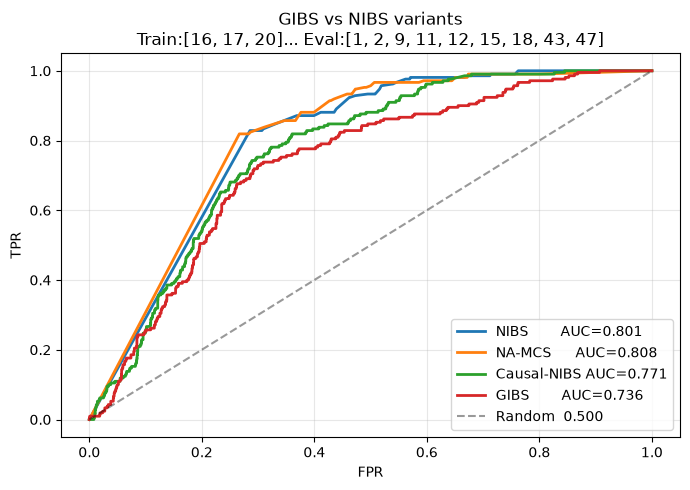

In [40]:
# ── GIBS Inference + AUROC ─────────────────────────────────────────────────────────────────────────
gibs_model.eval()
all_consensus_gibs = {}

for tid in tqdm(EVAL_TASKS, desc='GIBS inference'):
    task = tasks_map[tid]
    for s in sims_by_task.get(tid, []):
        try: sg = build_step_graph(s, info, task)
        except: continue
        nodes = [n for n in sg['nodes'] if n['type'] == 'AgentStep']
        if not nodes: continue
        idx   = {n['id']: i for i, n in enumerate(nodes)}
        ids   = set(idx)
        edges = {(idx[e['source']], idx[e['target']]): e['type']
                 for e in sg['edges'] if e['source'] in ids and e['target'] in ids}
        x   = encode_texts([n['op_text'] for n in nodes]).to(DEVICE)
        adj = build_adj_norm(len(nodes), edges).to(DEVICE)
        with torch.no_grad():
            p = gibs_model(x, adj).cpu().numpy()
        step_scores = {}
        pos = 0
        for idx_node, node in enumerate(sg['nodes']):
            if node['type'] != 'AgentStep': continue
            step_scores[idx_node] = {'m_gibs': float(p[pos])}
            pos += 1
        all_consensus_gibs[s['id']] = step_scores

print(f'Runs scored (GIBS): {len(all_consensus_gibs)}')

# AUROC
y_true, s_nibs, s_na, s_causal, s_gibs = [], [], [], [], []
for row in annots:
    sd1 = all_consensus.get(row['run_id'],        {}).get(int(row['step_idx']))
    sd2 = all_consensus_na.get(row['run_id'],     {}).get(int(row['step_idx']))
    sd5 = all_consensus_causal.get(row['run_id'], {}).get(int(row['step_idx']))
    sd6 = all_consensus_gibs.get(row['run_id'],   {}).get(int(row['step_idx']))
    if any(x is None for x in [sd1,sd2,sd5,sd6]): continue
    y_true.append(1 if row['label'] in ('incorrect','tool_error') else 0)
    s_nibs.append(1 - sd1['m_node'])
    s_na.append(1 - sd2['m_node'])
    s_causal.append(1 - sd5['m_causal'])
    s_gibs.append(1 - sd6['m_gibs'])

auc_nibs   = roc_auc_score(y_true, s_nibs)
auc_na     = roc_auc_score(y_true, s_na)
auc_causal = roc_auc_score(y_true, s_causal)
auc_gibs   = roc_auc_score(y_true, s_gibs)

print(f'Steps matched  : {len(y_true)}  (pos={sum(y_true)}, neg={len(y_true)-sum(y_true)})')
print(f'AUROC NIBS     : {auc_nibs:.4f}')
print(f'AUROC NA-MCS   : {auc_na:.4f}')
print(f'AUROC Causal   : {auc_causal:.4f}')
print(f'AUROC GIBS     : {auc_gibs:.4f}')

fig, ax = plt.subplots(figsize=(7,5))
for sc, lbl in [(s_nibs,   f'NIBS        AUC={auc_nibs:.3f}'),
                (s_na,     f'NA-MCS      AUC={auc_na:.3f}'),
                (s_causal, f'Causal-NIBS AUC={auc_causal:.3f}'),
                (s_gibs,   f'GIBS        AUC={auc_gibs:.3f}')]:
    fpr, tpr, _ = roc_curve(y_true, sc)
    ax.plot(fpr, tpr, lw=2, label=lbl)
ax.plot([0,1],[0,1],'k--',alpha=0.4,label='Random  0.500')
ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.set_title(f'GIBS vs NIBS variants\nTrain:{TRAIN_TASKS[:3]}... Eval:{EVAL_TASKS}')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(DRIVE_BASE + '/comparison_gibs_roc.png', dpi=150)
plt.show()

In [41]:
                                                                                                                                                                    
  # ── Transformer GIBS Model ───────────────────────────────────────────────────
                                                                                                                                                                                                    
  class TransformerGIBS(nn.Module):
      def __init__(self, embed_dim=384, d_model=128, nhead=4, num_layers=2, dropout=0.2):
          super().__init__()
          self.proj    = nn.Linear(embed_dim, d_model)
          enc_layer    = nn.TransformerEncoderLayer(
              d_model=d_model, nhead=nhead, dropout=dropout,
              batch_first=True, dim_feedforward=d_model*4
          )
          self.transformer = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
          self.head    = nn.Linear(d_model, 1)

      def forward(self, x):
          # x: (n_steps, embed_dim)
          n = x.size(0)
          x = self.proj(x)                                                  # (n, d_model)
          causal_mask = torch.triu(torch.ones(n, n, device=x.device), diagonal=1).bool()
          out = self.transformer(x.unsqueeze(0), mask=causal_mask)          # (1, n, d_model)
          return torch.sigmoid(self.head(out.squeeze(0))).squeeze(-1)       # (n,)

  tgibs_model = TransformerGIBS().to(DEVICE)
  print(f'TransformerGIBS params: {sum(p.numel() for p in tgibs_model.parameters()):,}')


TransformerGIBS params: 445,953


In [42]:
  # ── Transformer GIBS Training ────────────────────────────────────────────────
  import random

  TGIBS_MODEL_PATH = DRIVE_BASE + '/tgibs_model.pt'

  if os.path.exists(TGIBS_MODEL_PATH):
      tgibs_model.load_state_dict(torch.load(TGIBS_MODEL_PATH, map_location=DEVICE))
      tgibs_model.eval()
      print('Loaded cached TransformerGIBS model')
  else:
      optimizer = torch.optim.Adam(tgibs_model.parameters(), lr=1e-3)
      tgibs_model.train()

      for epoch in range(1, 31):
          total_loss = 0.0
          random.shuffle(all_train_data)
          for x, _, mask in all_train_data:   # adj_norm ignored — no graph needed
              x, mask = x.to(DEVICE), mask.to(DEVICE)
              optimizer.zero_grad()
              p    = tgibs_model(x)
              loss = ib_loss(p, mask)
              loss.backward()
              optimizer.step()
              total_loss += loss.item()
          if epoch % 5 == 0:
              print(f'Epoch {epoch:3d}/30  loss={total_loss/len(all_train_data):.4f}')

      torch.save(tgibs_model.state_dict(), TGIBS_MODEL_PATH)
      print(f'Training complete. Model saved to {TGIBS_MODEL_PATH}')


Loaded cached TransformerGIBS model


In [43]:
  tgibs_model.eval()
  all_consensus_tgibs = {}

  with tqdm(total=len(TASKS), desc='TGIBS inference', unit='task') as pbar:
      for tid in TASKS:
          task     = tasks_map[tid]
          all_sims = sims_by_task.get(tid, [])
          for sim in all_sims:
              try:
                  sg = build_step_graph(sim, info, task)
              except Exception:
                  continue

              # KEY FIX: keep track of original sg['nodes'] index, not agent_nodes index
              agent_nodes_with_idx = [
                  (i, n) for i, n in enumerate(sg['nodes'])
                  if n['type'] == 'AgentStep'
              ]
              if not agent_nodes_with_idx: continue

              texts = [n.get('op_text') or '' for _, n in agent_nodes_with_idx]
              x     = encode_texts(texts).to(DEVICE)
              with torch.no_grad():
                  p = tgibs_model(x)

              # use original sg node index as key (matches annotation step_idx)
              all_consensus_tgibs[sim['id']] = {
                  step_idx: {'m_tgibs': float(p[pos])}
                  for pos, (step_idx, _) in enumerate(agent_nodes_with_idx)
              }
          pbar.update(1)

  print(f'Runs scored (TGIBS): {len(all_consensus_tgibs)}')

  # ── AUROC ─────────────────────────────────────────────────────────────────────
  y_true, s_gcn, s_tf = [], [], []
  for row in annots:
      sd_g  = all_consensus_gibs.get(row['run_id'],  {}).get(int(row['step_idx']))
      sd_tf = all_consensus_tgibs.get(row['run_id'], {}).get(int(row['step_idx']))
      if sd_g is None or sd_tf is None: continue
      y_true.append(1 if row['label'] in ('incorrect', 'tool_error') else 0)
      s_gcn.append(1 - sd_g['m_gibs'])
      s_tf.append(1 - sd_tf['m_tgibs'])

  print(f'Steps matched    : {len(y_true)}  (pos={sum(y_true)}, neg={len(y_true)-sum(y_true)})')
  print(f'AUROC GCN-GIBS   : {roc_auc_score(y_true, s_gcn):.4f}')
  print(f'AUROC TF-GIBS    : {roc_auc_score(y_true, s_tf):.4f}')

TGIBS inference:   0%|          | 0/9 [00:00<?, ?task/s]

Runs scored (TGIBS): 180
Steps matched    : 2857  (pos=210, neg=2647)
AUROC GCN-GIBS   : 0.7358
AUROC TF-GIBS    : 0.5811
